# 01 · Limpeza e EDA — Aluguel São Paulo (capital)

**Projeto 1 do roadmap** — previsão do valor de aluguel (`rent`) de imóveis residenciais na cidade de São Paulo, com dados do QuintoAndar.

| Decisão | Valor |
|---|---|
| Escopo | Somente **São Paulo capital** |
| Alvo | `rent` (aluguel puro, R$/mês) |
| Custo total | Não é modelado. Estimado na UI com a **mediana por bairro** de `(totalCost − rent) / rent` |

**Saídas deste notebook** (nada em `data/processed/`, que é usado pelo monitoramento em produção):
- `data/interim/aluguel_sp_clean.parquet` — base limpa, pronta para inferência (02) e features (03)
- `data/interim/aluguel_custo_extra_bairro.parquet` — tabela de custo extra (condomínio + IPTU + taxas) por bairro, para a UI

**Roteiro**
1. Setup e carga
2. Escopo e tipagem
3. Colunas descartadas (vazamento e irrelevantes)
4. Duplicatas
5. Regras de qualidade e outliers (com log de limpeza)
6. Amenities e instalações → colunas binárias
7. Tabela de custo extra por bairro
8. EDA univariada
9. EDA bivariada (foco em `rent`)
10. Resumo e hipóteses para o notebook 02
11. Salvar

## 1. Setup e carga

In [1]:
from pathlib import Path
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

pd.options.display.float_format = "{:,.2f}".format
pd.set_option("display.max_columns", 60)

sns.set_theme(style="whitegrid", context="notebook")
COR = "#2a6f97"          # cor única para gráficos de uma série
RNG = 42


def achar_raiz(marcador: str = ".git") -> Path:
    """Sobe a partir do diretório atual até achar a raiz do repositório."""
    p = Path.cwd().resolve()
    for candidato in [p, *p.parents]:
        if (candidato / marcador).exists():
            return candidato
    raise FileNotFoundError(f"Raiz do projeto ({marcador}) não encontrada a partir de {p}")


ROOT = achar_raiz()
RAW_PATH = ROOT / "data/raw/quintoandar/quintoandar_sp_completo.parquet"
INTERIM = ROOT / "data/interim"
INTERIM.mkdir(parents=True, exist_ok=True)

OUT_CLEAN = INTERIM / "aluguel_sp_clean.parquet"
OUT_CUSTO = INTERIM / "aluguel_custo_extra_bairro.parquet"

ROOT

PosixPath('/home/felipe/Projeto/Portfolio/Portfolio2/Regression_PriceHouse')

In [2]:
raw = pd.read_parquet(RAW_PATH)
print(raw.shape)
raw.head(3)

(30413, 33)


,id,type,area,bathrooms,bedrooms,suites,parkingSpaces,amenities,installations,totalCost,rent,iptuPlusCondominium,salePrice,address,city,neighbourhood,regionName,isSecondaryHouse,location,coverImage,imageList,forRent,forSale,isPrimaryMarket,visitStatus,isFurnished,shortRentDescription,lat_viewport,lon_viewport,activeSpecialConditions,yield,yieldStrategy,categories
0,895407132,Casa,80.00,1.00,2.00,0.00,1.00,"[QUARTOS_E_CORREDORES_COM_PORTAS_AMPLAS, AREA_...",[VAGA_DE_GARAGEM_ACESSIVEL],1563,1500,0,0.00,Rua Arnaldo Estrella,São Paulo,Jardim Campinas,Cidade Dutra,False,"{'lat': -23.7728138, 'lon': -46.7075895}",original895407132-51.31256504655568IMG8950.jpeg,"[895407132-51.31256504655568IMG8950.jpeg, 8954...",True,False,False,ACCEPT_NEW,False,Casa para aluguel com 2 quartos.,-23.79,-46.71,None,NaN,None,None
1,895598034,Casa,50.00,1.00,1.00,0.00,0.00,"[VISTA_LIVRE, QUARTOS_E_CORREDORES_COM_PORTAS_...",[LAVANDERIA_NO_PREDIO],1355,1300,0,0.00,Rua Condé da Redinha,São Paulo,Jardim Novo Horizonte,Cidade Dutra,False,"{'lat': -23.7808073, 'lon': -46.6925286}",original895598034-50.76233494446214IMG0369.JPG,"[895598034-344.7056320566141IMG0367.JPG, 89559...",True,False,False,ACCEPT_NEW,False,Casa para aluguel com 1 quarto.,-23.79,-46.71,None,NaN,None,None
2,895521778,Casa,45.00,1.00,2.00,0.00,0.00,"[VISTA_LIVRE, QUARTOS_E_CORREDORES_COM_PORTAS_...",[],999,950,9,0.00,Rua Esther Lang,São Paulo,Jardim Morais Prado,Cidade Dutra,False,"{'lat': -23.7786133, 'lon': -46.6815718}",original895521778-225.016890146914162026062310...,[895521778-225.0168901469141620260623100048.jp...,True,False,False,ACCEPT_NEW,False,Casa para aluguel no Jardim Morais Prado com 2...,-23.79,-46.67,[Exclusivity],NaN,None,None


In [3]:
# Log de limpeza: cada etapa registra quantas linhas sobraram
log_limpeza = []


def registrar(etapa: str, df_: pd.DataFrame) -> None:
    anterior = log_limpeza[-1]["linhas"] if log_limpeza else len(df_)
    log_limpeza.append({"etapa": etapa, "linhas": len(df_), "removidas": anterior - len(df_)})


registrar("bruto", raw)

## 2. Escopo e tipagem

- Apenas `city == "São Paulo"`.
- Apenas `forRent == True`: anúncios só de venda trazem um `rent` que não é oferta real de aluguel.
- `location` (dict) → `lat` / `lon`, validados contra a caixa da capital.
- Strings normalizadas: `regionName` vem com `\xa0` (espaço não separável) no fim, e há bairros com e sem acento (`Jardim Ampliacao` / `Jardim Ampliação`), unificados na grafia mais frequente.

In [4]:
df = raw[raw["city"] == "São Paulo"].copy()
registrar("city == São Paulo", df)

df = df[df["forRent"].astype(bool)].copy()
registrar("forRent == True", df)

df["lat"] = df["location"].str["lat"]
df["lon"] = df["location"].str["lon"]


def limpar_texto(s: pd.Series) -> pd.Series:
    return (
        s.astype("string")
        .map(lambda x: unicodedata.normalize("NFKC", x) if pd.notna(x) else x)
        .str.replace("\xa0", " ", regex=False)
        .str.strip()
    )


for col in ["neighbourhood", "regionName", "address", "type"]:
    df[col] = limpar_texto(df[col])



def unificar_grafia(s: pd.Series) -> pd.Series:
    """'Jardim Ampliacao' e 'Jardim Ampliação' viram a grafia mais frequente do grupo."""
    chave = (
        s.str.lower()
        .map(lambda x: unicodedata.normalize("NFKD", x).encode("ascii", "ignore").decode() if pd.notna(x) else x)
    )
    canonica = s.groupby(chave).agg(lambda g: g.value_counts().index[0])
    return chave.map(canonica).astype("string")


for col in ["neighbourhood", "regionName"]:
    antes = df[col].nunique()
    df[col] = unificar_grafia(df[col])
    print(f"{col}: {antes} -> {df[col].nunique()} grafias")

df["isFurnished"] = df["isFurnished"].astype("boolean")
for col in ["bathrooms", "bedrooms", "suites", "parkingSpaces"]:
    df[col] = df[col].astype("Int64")

df[["neighbourhood", "regionName", "type", "lat", "lon"]].describe(include="all").T

neighbourhood: 1403 -> 1257 grafias
regionName: 321 -> 321 grafias


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
neighbourhood,23505,1257,Pinheiros,642,NaN,NaN,NaN,NaN,NaN,NaN,NaN
regionName,23505,321,Santana,724,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,23505,4,Apartamento,14299,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lat,"23,505.00",NaN,NaN,NaN,-23.56,0.05,-23.78,-23.60,-23.56,-23.53,-23.40
lon,"23,505.00",NaN,NaN,NaN,-46.63,0.08,-46.84,-46.69,-46.64,-46.58,-46.38


In [5]:
# Caixa aproximada do município de São Paulo
LAT_MIN, LAT_MAX = -24.01, -23.35
LON_MIN, LON_MAX = -46.83, -46.36

dentro_sp = df["lat"].between(LAT_MIN, LAT_MAX) & df["lon"].between(LON_MIN, LON_MAX)
print(f"Fora da caixa da capital: {(~dentro_sp).sum()}")
df = df[dentro_sp].copy()
registrar("lat/lon dentro da capital", df)

Fora da caixa da capital: 1


## 3. Colunas descartadas

**Vazamento do alvo** — não podem ser features, porque são calculadas a partir de `rent` ou só existem depois dele:

| Coluna | Motivo |
|---|---|
| `totalCost` | `rent` + `iptuPlusCondominium` + taxas. Usada só na tabela de custo extra (seção 7) |
| `yield`, `yieldStrategy` | Rentabilidade = aluguel / preço de venda |
| `salePrice`, `forSale` | Só existe para ~42% dos imóveis (0 nos demais); preço de venda é praticamente outro alvo |

**`iptuPlusCondominium` fica**, mas como candidata a feature com ressalva: é conhecida no momento do anúncio, porém na UI o usuário precisaria informá-la. A decisão (usar ou não) fica para o notebook 04, comparando o modelo com e sem ela.

**Irrelevantes ou constantes**: identificadores de mídia, flags quase constantes e colunas redundantes.

In [6]:
print("isSecondaryHouse:", df["isSecondaryHouse"].value_counts().to_dict())
print("isPrimaryMarket :", df["isPrimaryMarket"].value_counts().to_dict())
print("visitStatus     :", df["visitStatus"].value_counts().to_dict())
print("categories nulos:", f'{df["categories"].isna().mean():.1%}')

isSecondaryHouse: {False: 23504}
isPrimaryMarket : {False: 23500, True: 4}
visitStatus     : {'ACCEPT_NEW': 23274, 'ACCEPT_ALWAYS': 229, 'BLOCKED': 1}
categories nulos: 96.5%


In [7]:
COLS_VAZAMENTO = ["yield", "yieldStrategy", "salePrice", "forSale"]   # totalCost fica até a seção 7
COLS_IRRELEVANTES = [
    "location", "lat_viewport", "lon_viewport",          # já extraídos para lat/lon
    "coverImage", "imageList",                           # mídia
    "city", "forRent",                                   # constantes após o filtro
    "isSecondaryHouse", "isPrimaryMarket", "visitStatus",  # quase constantes
    "categories",                                        # >95% nulo
]

df = df.drop(columns=COLS_VAZAMENTO + COLS_IRRELEVANTES)

# activeSpecialConditions -> flags simples (Exclusivity / Negotiated)
cond = df["activeSpecialConditions"].map(lambda x: list(x) if x is not None else [])
df["cond_exclusividade"] = cond.map(lambda l: "Exclusivity" in l).astype(int)
df["cond_negociado"] = cond.map(lambda l: "Negotiated" in l).astype(int)
df = df.drop(columns="activeSpecialConditions")

df.columns.tolist()

['id',
 'type',
 'area',
 'bathrooms',
 'bedrooms',
 'suites',
 'parkingSpaces',
 'amenities',
 'installations',
 'totalCost',
 'rent',
 'iptuPlusCondominium',
 'address',
 'neighbourhood',
 'regionName',
 'isFurnished',
 'shortRentDescription',
 'lat',
 'lon',
 'cond_exclusividade',
 'cond_negociado']

## 4. Duplicatas

Não há `id` repetido, mas o mesmo imóvel aparece republicado com `id` diferente (mesma coordenada, área, cômodos e preço).
Duplicatas inflam a métrica: a mesma unidade cai no treino e no teste.

In [8]:
CHAVE_DUP = ["lat", "lon", "area", "bedrooms", "bathrooms", "parkingSpaces", "rent", "iptuPlusCondominium"]

print("id duplicado          :", df["id"].duplicated().sum())
print("duplicata pela chave  :", df.duplicated(subset=CHAVE_DUP).sum())
print("mesma chave, rent ≠   :", df.duplicated(subset=[c for c in CHAVE_DUP if c != "rent"]).sum()
      - df.duplicated(subset=CHAVE_DUP).sum())

df = df.drop_duplicates(subset=CHAVE_DUP, keep="first").copy()
registrar("remove duplicatas (chave física + preço)", df)

id duplicado          : 0
duplicata pela chave  : 1003
mesma chave, rent ≠   : 381


> **Nota:** imóveis com a mesma chave física mas `rent` diferente (re-anúncio com novo preço) foram mantidos.
> No notebook 04, usar `GroupKFold` por coordenada evita que esses pares fiquem separados entre treino e teste.

## 5. Regras de qualidade e outliers

As regras são de **domínio** (valores impossíveis ou de erro de cadastro), não estatísticas cegas.
O objetivo é tirar erro, não tirar imóvel caro: um apartamento de R$ 30 mil no Jardim Europa é real.

| Regra | Justificativa |
|---|---|
| `area`, `bedrooms`, `bathrooms` não nulos | Atributos essenciais |
| `12 ≤ area ≤ 1000` m² | <12 m² é erro (ex.: apartamento de 3 m²); >1000 m² são terrenos/galpões ou erro de digitação |
| `bathrooms ≥ 1` | Imóvel residencial sem banheiro = erro |
| `bedrooms ≥ 1`, exceto Studio | Studio pode ter 0 quartos |
| `rent / area` entre P0,5% e P99,5% | Pega erros de unidade na área (ex.: casa de 4.200 m² por R$ 1.800) |
| `iptuPlusCondominium > 3 × rent` → `NaN` | Valor de condomínio/IPTU absurdo (ex.: R$ 3,2 mi). Mantém a linha, apaga só o valor |

In [9]:
num_cols = ["rent", "totalCost", "iptuPlusCondominium", "area", "bedrooms", "bathrooms", "suites", "parkingSpaces"]
df[num_cols].quantile([0, .001, .01, .25, .5, .75, .99, .999, 1]).T

,0.00,0.00,0.01,0.25,0.50,0.75,0.99,1.00,1.00
rent,500.00,760.00,945.00,"1,900.00","2,800.00","4,500.00","21,880.00","34,700.00","35,000.00"
totalCost,521.00,864.50,"1,093.00","2,374.00","3,506.00","5,669.00","27,164.00","43,819.50","3,217,941.00"
iptuPlusCondominium,0.00,0.00,0.00,280.00,525.00,908.00,"5,900.00","17,258.00","3,207,167.00"
area,0.00,12.00,18.00,34.00,50.00,98.00,588.06,"1,140.24","62,982.00"
bedrooms,0,0,1,1,2,2,5,8,18
bathrooms,0,1,1,1,1,2,6,9,12
suites,0,0,0,0,0,1,4,5,12
parkingSpaces,0.00,0.00,0.00,0.00,1.00,1.00,8.00,12.50,20.00


In [10]:
df = df.dropna(subset=["area", "bedrooms", "bathrooms"]).copy()
registrar("remove nulos em area/bedrooms/bathrooms", df)

df = df[df["area"].between(12, 1000)].copy()
registrar("12 <= area <= 1000", df)

df = df[df["bathrooms"] >= 1].copy()
registrar("bathrooms >= 1", df)

df = df[(df["bedrooms"] >= 1) | (df["type"] == "StudioOuKitchenette")].copy()
registrar("bedrooms >= 1 (exceto studio)", df)

df["rent_m2"] = df["rent"] / df["area"]
lo, hi = df["rent_m2"].quantile([0.005, 0.995])
print(f"Faixa aceita de R$/m²: {lo:,.1f} a {hi:,.1f}")
df = df[df["rent_m2"].between(lo, hi)].copy()
registrar("rent/m² entre P0,5 e P99,5", df)

absurdo = df["iptuPlusCondominium"] > 3 * df["rent"]
print(f"iptuPlusCondominium absurdo -> NaN: {absurdo.sum()}")
df["iptuPlusCondominium"] = df["iptuPlusCondominium"].astype("float").mask(absurdo)

Faixa aceita de R$/m²: 10.3 a 208.3
iptuPlusCondominium absurdo -> NaN: 22


### Teto do alvo

O QuintoAndar parece limitar a busca em R$ 35 mil: há um acúmulo de anúncios exatamente nesse valor.
Isso indica **censura à direita** — o modelo não vai aprender bem acima disso. Mantemos os registros e documentamos a limitação.

In [11]:
print("rent == 35.000:", (df["rent"] == 35_000).sum())
print("rent >= 30.000:", (df["rent"] >= 30_000).sum())
print("rent máximo   :", df["rent"].max())

rent == 35.000: 15
rent >= 30.000: 44
rent máximo   : 35000


In [12]:
log_df = pd.DataFrame(log_limpeza)
log_df["% do bruto"] = log_df["linhas"] / log_df["linhas"].iloc[0]
log_df["% do bruto"] = log_df["% do bruto"].map("{:.1%}".format)
log_df

,etapa,linhas,removidas,% do bruto
0,bruto,30413,0,100.0%
1,city == São Paulo,24250,6163,79.7%
2,forRent == True,23505,745,77.3%
3,lat/lon dentro da capital,23504,1,77.3%
4,remove duplicatas (chave física + preço),22501,1003,74.0%
5,remove nulos em area/bedrooms/bathrooms,22498,3,74.0%
6,12 <= area <= 1000,22453,45,73.8%
7,bathrooms >= 1,22450,3,73.8%
8,bedrooms >= 1 (exceto studio),22436,14,73.8%
9,"rent/m² entre P0,5 e P99,5",22213,223,73.0%


## 6. Amenities e instalações → colunas binárias

- `amenities` (60 valores): características da unidade (varanda, mobília, aceita pet...)
- `installations` (18 valores): áreas comuns do condomínio (piscina, academia...)

Mantemos só os itens presentes em pelo menos 1% dos anúncios. Prefixos `am_` e `inst_` evitam colisão (ex.: `CHURRASQUEIRA` existe nas duas).

In [13]:
def multi_hot(serie: pd.Series, prefixo: str, min_freq: float = 0.01) -> pd.DataFrame:
    listas = serie.map(lambda x: list(x) if x is not None else [])
    dummies = (
        listas.explode()
        .dropna()
        .pipe(pd.get_dummies)
        .groupby(level=0).max()
        .reindex(serie.index, fill_value=False)
        .astype(int)
    )
    dummies = dummies.loc[:, dummies.mean() >= min_freq]
    dummies.columns = [f"{prefixo}{c.lower()}" for c in dummies.columns]
    return dummies


am = multi_hot(df["amenities"], "am_")
inst = multi_hot(df["installations"], "inst_")
df = pd.concat([df.drop(columns=["amenities", "installations"]), am, inst], axis=1)

df["n_amenities"] = am.sum(axis=1)
df["n_instalacoes"] = inst.sum(axis=1)

AM_COLS, INST_COLS = am.columns.tolist(), inst.columns.tolist()
print(f"{len(AM_COLS)} amenities, {len(INST_COLS)} instalações")

55 amenities, 18 instalações


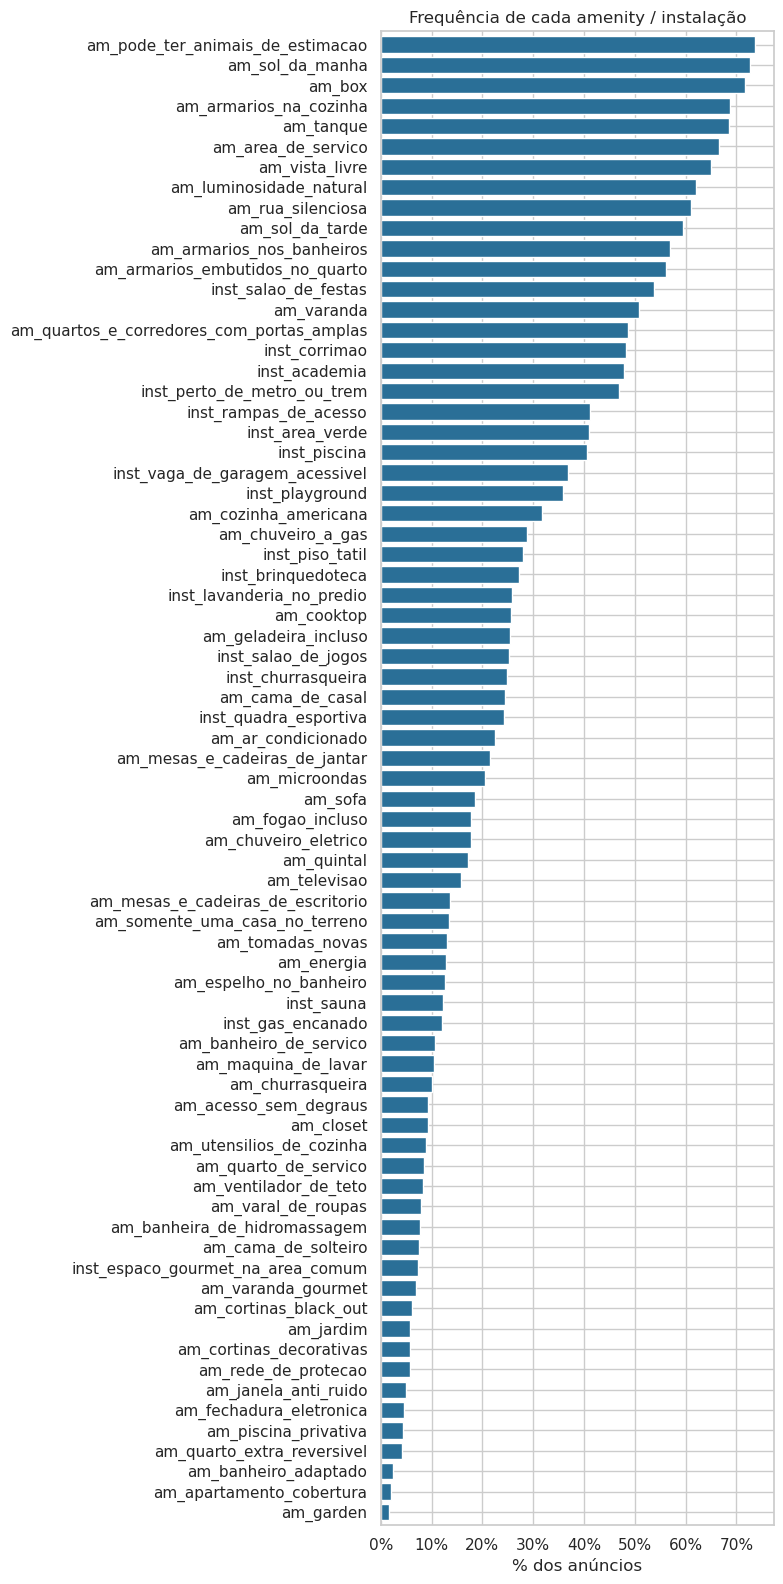

In [14]:
freq = pd.concat([am, inst], axis=1).mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 16))
freq.plot.barh(ax=ax, color=COR, width=0.8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Frequência de cada amenity / instalação")
ax.set_xlabel("% dos anúncios")
plt.tight_layout()
plt.show()

## 7. Tabela de custo extra por bairro (para a UI)

`custo_extra = totalCost − rent` (condomínio + IPTU + taxa de serviço/seguro).
Na UI: **custo total estimado = aluguel previsto × (1 + mediana do % extra do bairro)**.

Usamos a **mediana da razão por anúncio**, robusta aos valores absurdos de condomínio.
Bairro com poucos anúncios não gera mediana confiável, então há um fallback hierárquico:

`neighbourhood` (n ≥ 20) → `regionName` (n ≥ 20) → mediana da cidade.

> A tabela usa todos os anúncios limpos. Ela é uma estatística descritiva para a UI, não feature do modelo — por isso não há risco de vazamento.

In [15]:
MIN_N = 20

custo = df[["neighbourhood", "regionName", "rent", "totalCost", "iptuPlusCondominium"]].copy()
custo["custo_extra"] = custo["totalCost"] - custo["rent"]
custo["pct_extra"] = custo["custo_extra"] / custo["rent"]
custo = custo[custo["iptuPlusCondominium"].notna()]   # exclui condomínios absurdos


def resumo(g):
    return pd.Series({
        "n": len(g),
        "pct_extra_mediana": g["pct_extra"].median(),
        "pct_extra_p25": g["pct_extra"].quantile(0.25),
        "pct_extra_p75": g["pct_extra"].quantile(0.75),
        "custo_extra_mediana": g["custo_extra"].median(),
    })


por_bairro = custo.groupby("neighbourhood").apply(resumo)
por_regiao = custo.groupby("regionName").apply(resumo)
cidade = resumo(custo)

# Mapeia cada bairro para a região mais frequente dele (para o fallback)
bairro_regiao = custo.groupby("neighbourhood")["regionName"].agg(lambda s: s.mode().iat[0])

linhas = []
for bairro, regiao in bairro_regiao.items():
    if por_bairro.loc[bairro, "n"] >= MIN_N:
        fonte, stats = "bairro", por_bairro.loc[bairro]
    elif regiao in por_regiao.index and por_regiao.loc[regiao, "n"] >= MIN_N:
        fonte, stats = "regiao", por_regiao.loc[regiao]
    else:
        fonte, stats = "cidade", cidade
    linhas.append({"neighbourhood": bairro, "regionName": regiao, "fonte": fonte,
                   "n_bairro": int(por_bairro.loc[bairro, "n"]), **stats.drop("n").to_dict()})

custo_bairro = pd.DataFrame(linhas).sort_values("pct_extra_mediana", ascending=False)

print(f"Mediana da cidade: {cidade['pct_extra_mediana']:.1%} ({cidade['custo_extra_mediana']:,.0f} R$)")
print(custo_bairro["fonte"].value_counts().to_dict())
custo_bairro.head(15)

Mediana da cidade: 23.6% (644 R$)
{'regiao': 775, 'bairro': 256, 'cidade': 218}


,neighbourhood,regionName,fonte,n_bairro,pct_extra_mediana,pct_extra_p25,pct_extra_p75,custo_extra_mediana
175,Higienópolis,Higienópolis,bairro,27,0.52,0.26,0.82,"3,794.00"
681,Paraíso do Morumbi,Panamby,bairro,47,0.45,0.31,0.63,"1,791.00"
206,Jardim Ampliacao,Panamby,bairro,64,0.45,0.32,0.60,"1,626.00"
754,Parque Vila Maria,Parque Novo Mundo,regiao,1,0.43,0.31,0.53,518.00
211,Jardim Andarai,Parque Novo Mundo,regiao,2,0.43,0.31,0.53,518.00
1202,Vila Suzana,Portal do Morumbi,bairro,116,0.43,0.32,0.60,"1,640.50"
653,Lar São Paulo,Portal do Morumbi,regiao,3,0.43,0.31,0.60,"1,613.00"
627,Jardim das Palmas,Portal do Morumbi,regiao,3,0.43,0.31,0.60,"1,613.00"
405,Jardim Maria Duarte,Portal do Morumbi,regiao,2,0.43,0.31,0.60,"1,613.00"
447,Jardim Novo Taboão,Portal do Morumbi,regiao,3,0.43,0.31,0.60,"1,613.00"


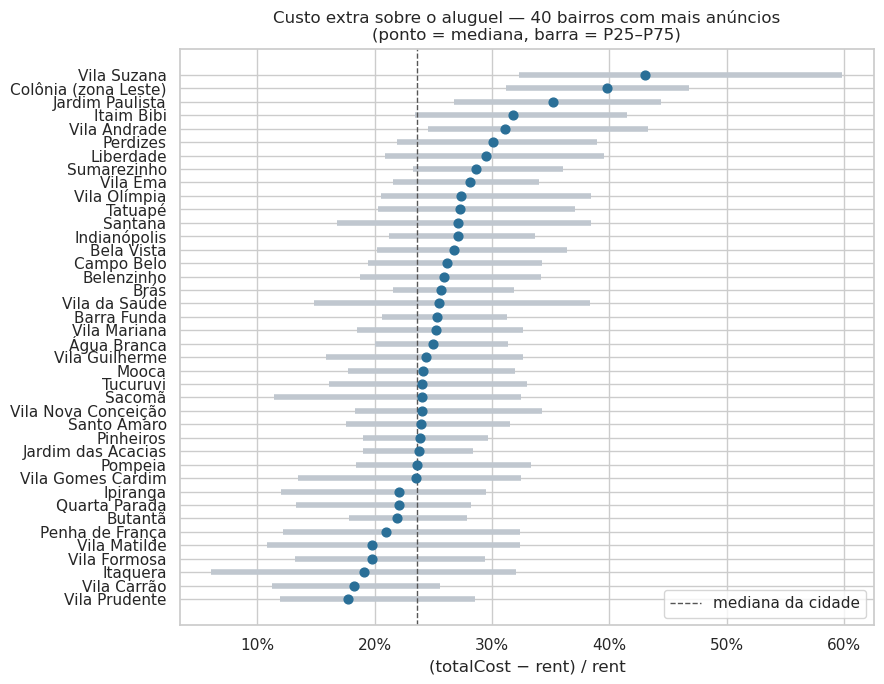

In [16]:
top = (
    custo_bairro[custo_bairro["fonte"] == "bairro"]
    .nlargest(40, "n_bairro")
    .sort_values("pct_extra_mediana")
)
fig, ax = plt.subplots(figsize=(9, 7))
ax.hlines(top["neighbourhood"], top["pct_extra_p25"], top["pct_extra_p75"], color="#c0c7cf", lw=4)
ax.scatter(top["pct_extra_mediana"], top["neighbourhood"], color=COR, s=40, zorder=3)
ax.axvline(cidade["pct_extra_mediana"], color="#555", ls="--", lw=1, label="mediana da cidade")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Custo extra sobre o aluguel — 40 bairros com mais anúncios\n(ponto = mediana, barra = P25–P75)")
ax.set_xlabel("(totalCost − rent) / rent")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [18]:
# totalCost não é mais necessário
df = df.drop(columns="totalCost")

## 8. EDA univariada

### 8.1 Alvo: `rent`
Esperado: assimetria forte à direita. O log deve deixar a distribuição próxima da normal, o que indica modelar `log(rent)` (e reportar as métricas de volta em R$).

count   22,213.00
mean     4,073.90
std      3,928.90
min        550.00
5%       1,200.00
25%      1,890.00
50%      2,800.00
75%      4,500.00
95%     12,000.00
max     35,000.00

Assimetria rent    : 3.10
Assimetria log_rent: 0.75


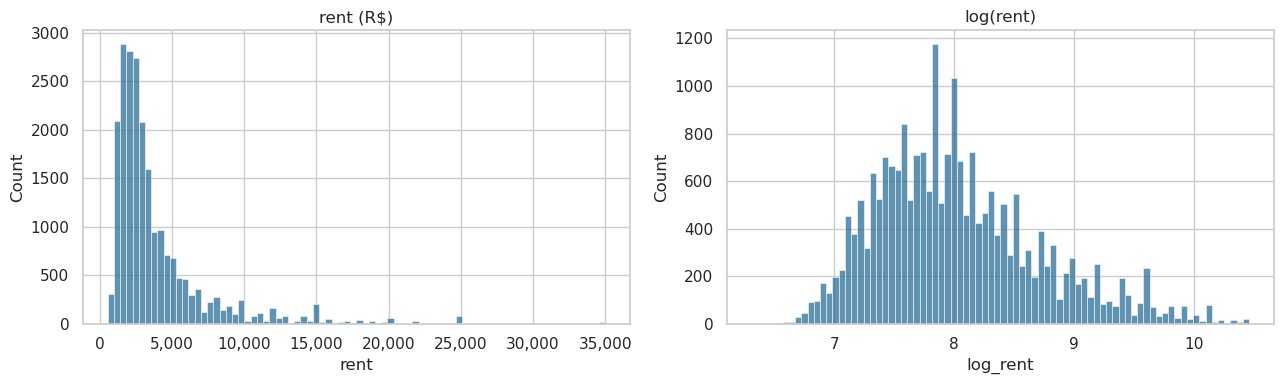

In [19]:
df["log_rent"] = np.log(df["rent"])

print(df["rent"].describe(percentiles=[.05, .25, .5, .75, .95]).to_string())
print(f"\nAssimetria rent    : {df['rent'].skew():.2f}")
print(f"Assimetria log_rent: {df['log_rent'].skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["rent"], bins=80, ax=axes[0], color=COR)
axes[0].set_title("rent (R$)")
axes[0].xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
sns.histplot(df["log_rent"], bins=80, ax=axes[1], color=COR)
axes[1].set_title("log(rent)")
plt.tight_layout()
plt.show()

### 8.2 Numéricas

In [20]:
NUM_FEATS = ["area", "bedrooms", "bathrooms", "suites", "parkingSpaces",
             "iptuPlusCondominium", "rent_m2", "n_amenities", "n_instalacoes"]


def estatisticas(d: pd.DataFrame) -> pd.DataFrame:
    s = d.describe(percentiles=[.01, .5, .99]).T
    s["nulos"] = d.isna().sum()
    s["assimetria"] = d.skew()
    s["curtose"] = d.kurt()
    return s


estatisticas(df[NUM_FEATS].astype(float))

,count,mean,std,min,1%,50%,99%,max,nulos,assimetria,curtose
area,"22,213.00",92.38,109.46,12.00,19.00,50.00,546.76,"1,000.00",0,3.10,12.43
bedrooms,"22,213.00",1.97,1.05,0.00,1.00,2.00,5.00,18.00,0,1.64,6.78
bathrooms,"22,213.00",1.69,1.24,1.00,1.00,1.00,6.00,12.00,0,2.21,5.42
suites,"22,213.00",0.57,0.91,0.00,0.00,0.00,4.00,12.00,0,2.12,6.01
parkingSpaces,"22,213.00",1.06,1.53,0.00,0.00,1.00,7.00,20.00,0,2.87,14.31
iptuPlusCondominium,"22,191.00",823.99,"1,149.46",0.00,0.00,525.00,"5,617.80","21,900.00",22,5.19,45.70
rent_m2,"22,213.00",58.55,34.36,10.33,13.69,49.44,168.00,208.33,0,1.24,1.43
n_amenities,"22,213.00",13.89,7.30,0.00,1.00,13.00,35.00,53.00,0,0.62,0.45
n_instalacoes,"22,213.00",5.79,4.45,0.00,0.00,5.00,15.00,17.00,0,0.30,-1.16


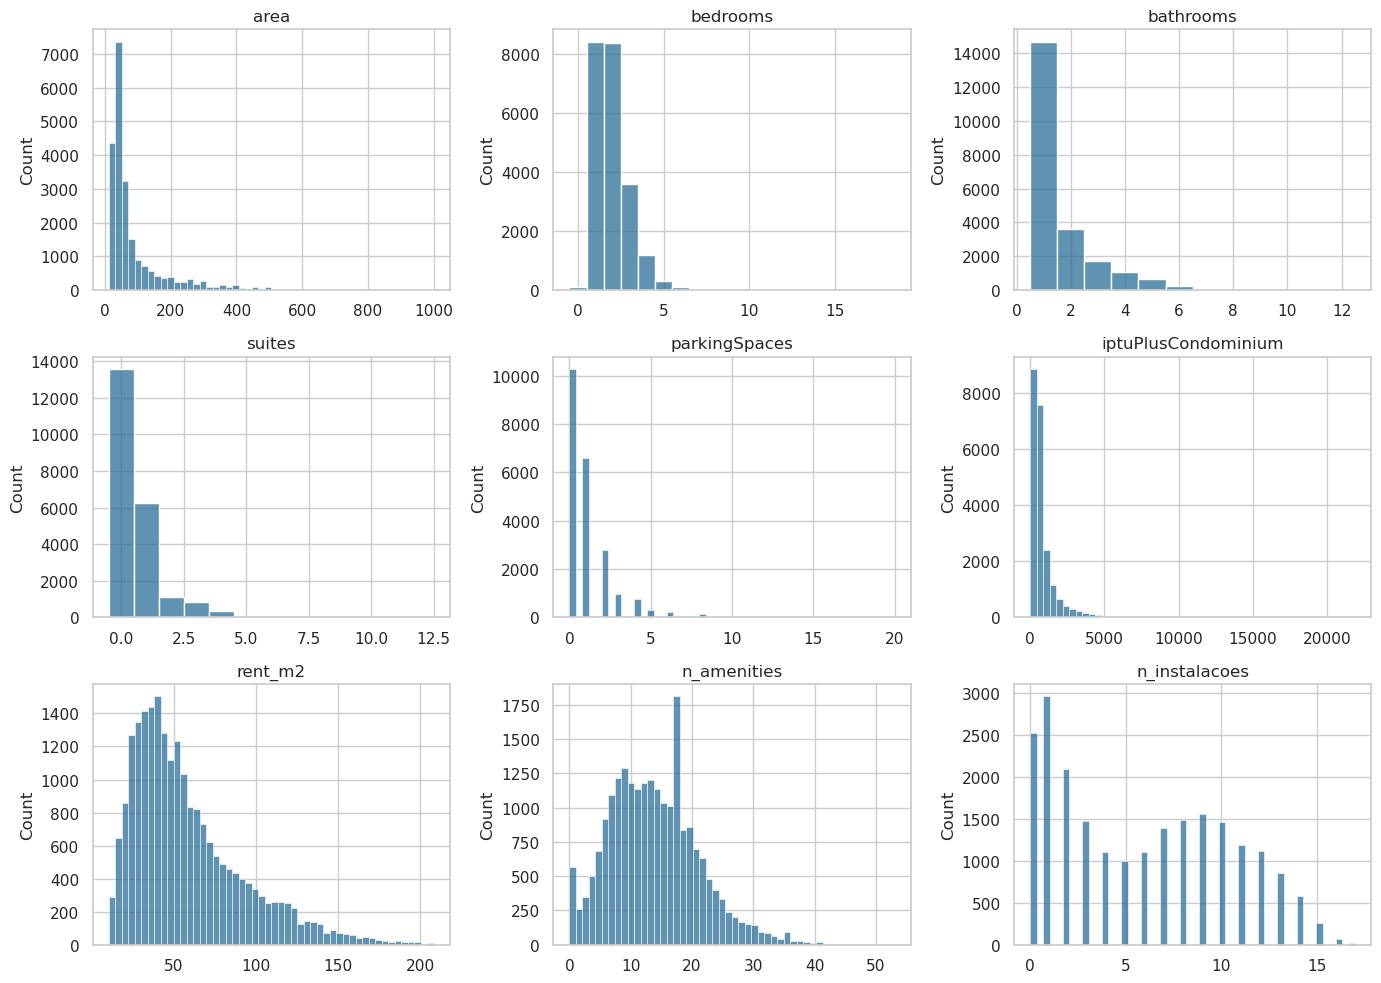

In [21]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, NUM_FEATS):
    serie = df[col].dropna().astype(float)
    discreta = serie.nunique() <= 15
    sns.histplot(serie, ax=ax, color=COR, discrete=discreta, bins=None if discreta else 50)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

### 8.3 Categóricas

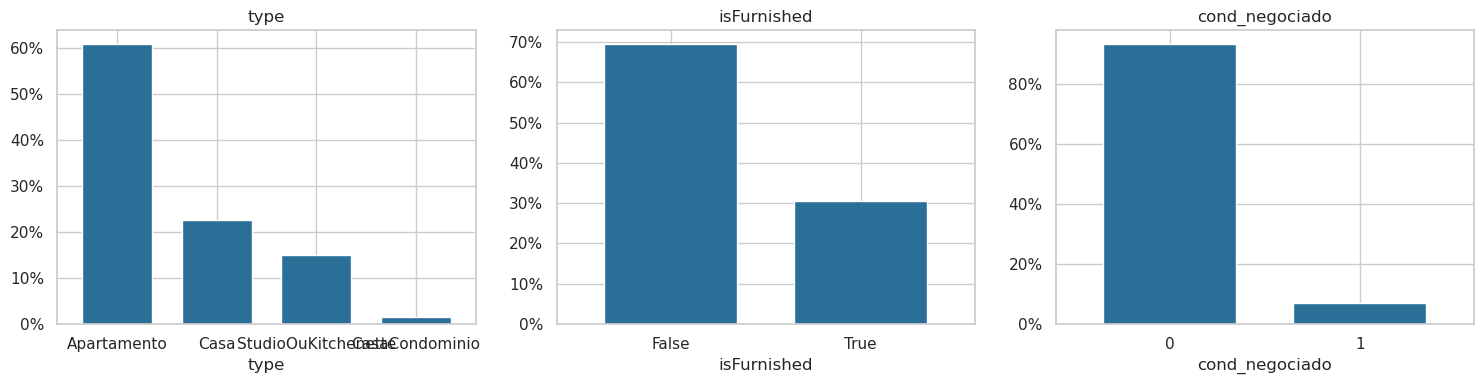

Bairros (neighbourhood): 1249
Regiões (regionName)   : 319

Anúncios por bairro:
count   1,249.00
mean       17.80
std        43.30
min         1.00
25%         2.00
50%         5.00
75%        15.00
90%        41.00
max       611.00


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["type", "isFurnished", "cond_negociado"]):
    vc = df[col].astype(str).value_counts(normalize=True)
    vc.plot.bar(ax=ax, color=COR, width=0.7)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print("Bairros (neighbourhood):", df["neighbourhood"].nunique())
print("Regiões (regionName)   :", df["regionName"].nunique())
print("\nAnúncios por bairro:")
print(df["neighbourhood"].value_counts().describe(percentiles=[.25, .5, .75, .9]).round(1).to_string())

> **Cardinalidade:** `neighbourhood` tem muitos níveis com poucos anúncios (mediana ≈ 4).
> Em modelos lineares e ANOVA isso não funciona bem. Opções para o 03: agrupar raros, target encoding dentro do CV, ou trocar o bairro por coordenadas + distâncias (POIs).

## 9. EDA bivariada (foco em `rent`)

Usamos a **mediana** e correlação de **Spearman**: o alvo é assimétrico e tem outliers legítimos.

### 9.1 Área × aluguel (escala log-log)

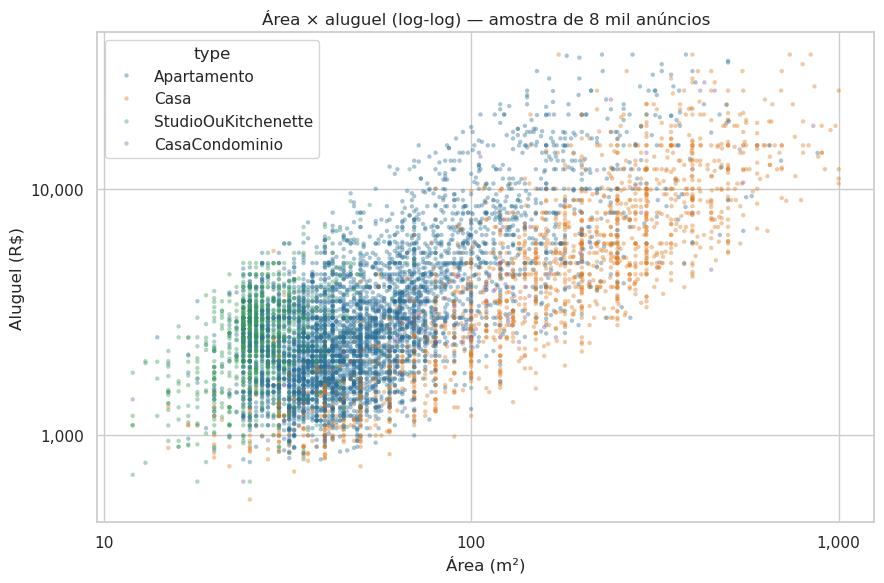

Elasticidade aproximada (inclinação log-log): 0.61


In [23]:
fig, ax = plt.subplots(figsize=(9, 6))
tipos = ["Apartamento", "Casa", "StudioOuKitchenette", "CasaCondominio"]
paleta = dict(zip(tipos, ["#2a6f97", "#e07a1f", "#3a9d5d", "#8e5ba8"]))
sns.scatterplot(data=df.sample(min(len(df), 8000), random_state=RNG), x="area", y="rent",
                hue="type", hue_order=tipos, palette=paleta, s=10, alpha=0.4, linewidth=0, ax=ax)
ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Área × aluguel (log-log) — amostra de 8 mil anúncios")
ax.set_xlabel("Área (m²)")
ax.set_ylabel("Aluguel (R$)")
plt.tight_layout()
plt.show()

print(f"Elasticidade aproximada (inclinação log-log): "
      f"{np.polyfit(np.log(df['area']), df['log_rent'], 1)[0]:.2f}")

**Área e preço:** a elasticidade log-log é cerca de 0,61, ou seja, cada m² a mais vale menos em imóvel grande.

### 9.2 Aluguel por tipo, quartos, vagas e mobília

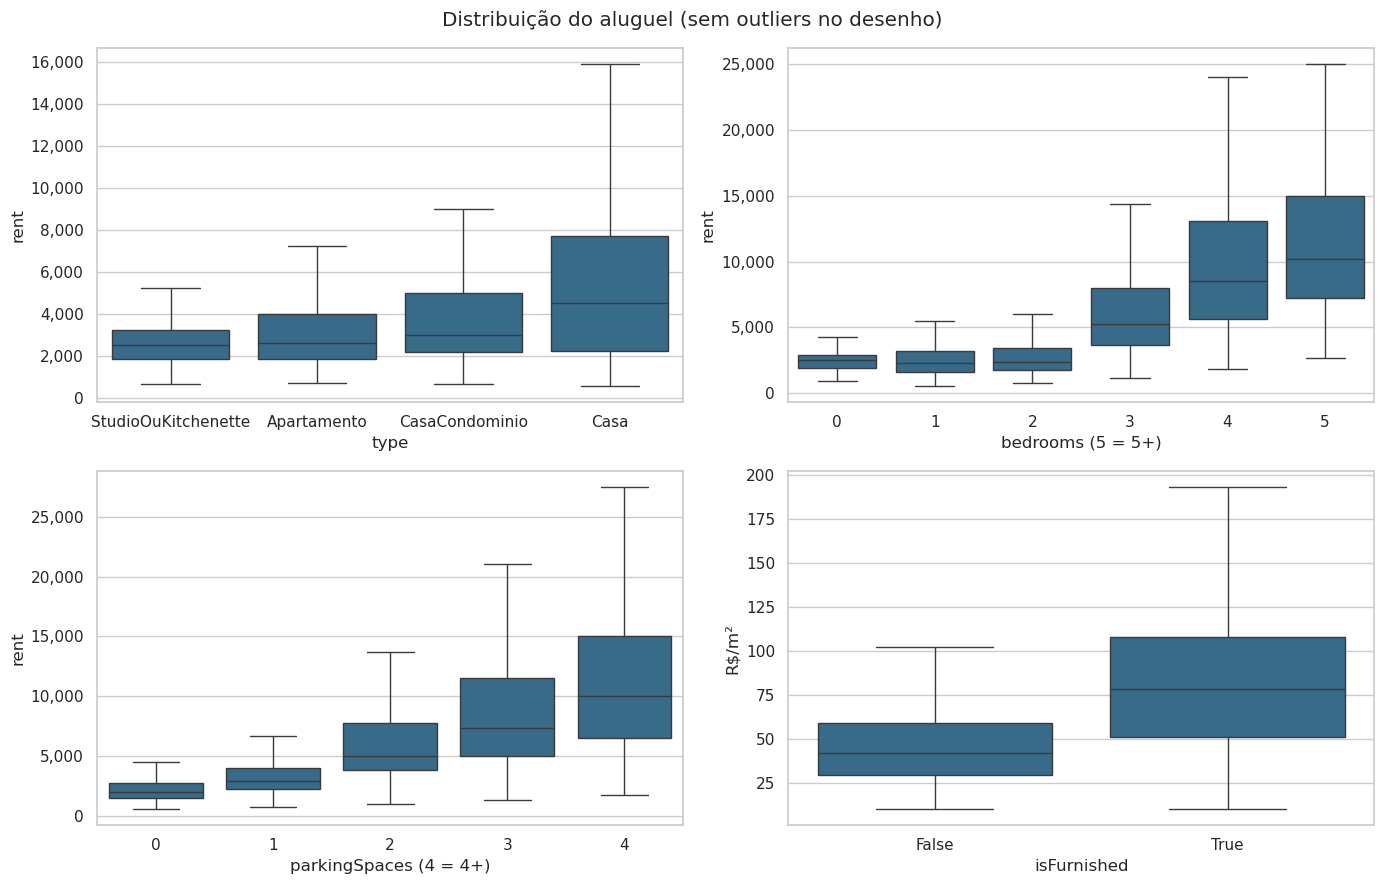

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

ordem_tipo = df.groupby("type")["rent"].median().sort_values().index
sns.boxplot(data=df, x="type", y="rent", order=ordem_tipo, ax=axes[0, 0], color=COR, showfliers=False)

df["bedrooms_cap"] = df["bedrooms"].clip(upper=5)
sns.boxplot(data=df, x="bedrooms_cap", y="rent", ax=axes[0, 1], color=COR, showfliers=False)
axes[0, 1].set_xlabel("bedrooms (5 = 5+)")

df["parking_cap"] = df["parkingSpaces"].clip(upper=4)
sns.boxplot(data=df, x="parking_cap", y="rent", ax=axes[1, 0], color=COR, showfliers=False)
axes[1, 0].set_xlabel("parkingSpaces (4 = 4+)")

sns.boxplot(data=df, x="isFurnished", y="rent_m2", ax=axes[1, 1], color=COR, showfliers=False)
axes[1, 1].set_ylabel("R$/m²")

for ax in axes.flat:
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
fig.suptitle("Distribuição do aluguel (sem outliers no desenho)")
plt.tight_layout()
plt.show()

df = df.drop(columns=["bedrooms_cap", "parking_cap"])

> Mobília é comparada em **R$/m²**: imóveis mobiliados tendem a ser menores (studios), então comparar o `rent` bruto confunde o efeito com o tamanho.

### 9.3 Geografia: R$/m² no mapa

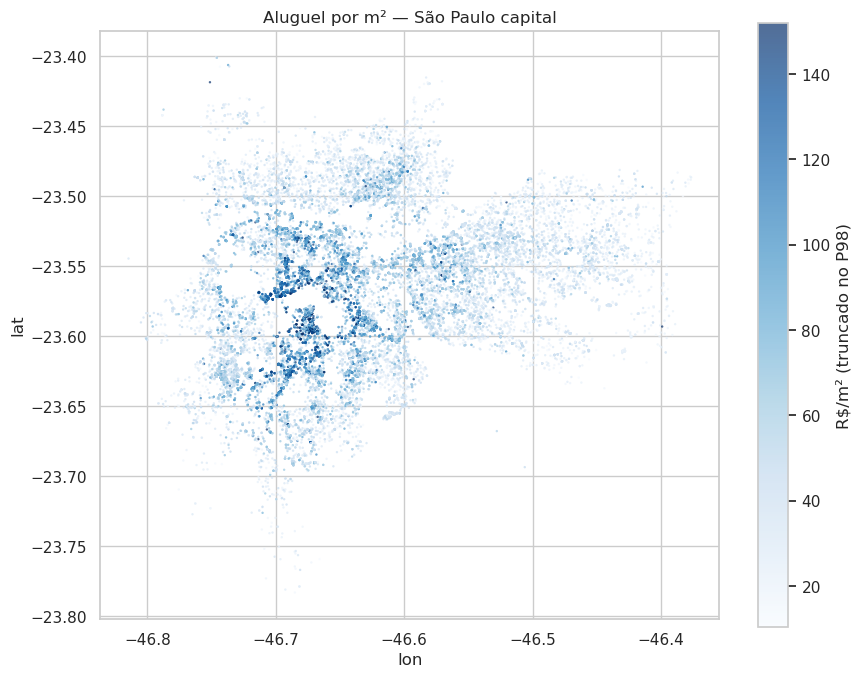

In [25]:
fig, ax = plt.subplots(figsize=(9, 9))
sc = ax.scatter(df["lon"], df["lat"], c=df["rent_m2"].clip(upper=df["rent_m2"].quantile(.98)),
                cmap="Blues", s=3, alpha=0.7, linewidths=0)
ax.set_aspect(1 / np.cos(np.radians(-23.55)))
ax.set_title("Aluguel por m² — São Paulo capital")
ax.set_xlabel("lon")
ax.set_ylabel("lat")
cb = fig.colorbar(sc, ax=ax, shrink=0.7)
cb.set_label("R$/m² (truncado no P98)")
plt.tight_layout()
plt.show()

### 9.3.1 Onde está cada tipo de imóvel

**Hipótese:** studios se concentram em áreas nobres e centrais.

Três evidências, da mais visual à mais objetiva:
1. Mapa de cada tipo sobre o fundo de todos os anúncios.
2. Mix de tipos por faixa de distância ao centro (Praça da Sé).
3. Por região: % de studios × R$/m² mediano (proxy de "área nobre"), com correlação de Spearman.

`dist_centro_km` é criada aqui e fica na base: é determinística (só depende de lat/lon), sem risco de vazamento, e vira candidata a feature no 03.

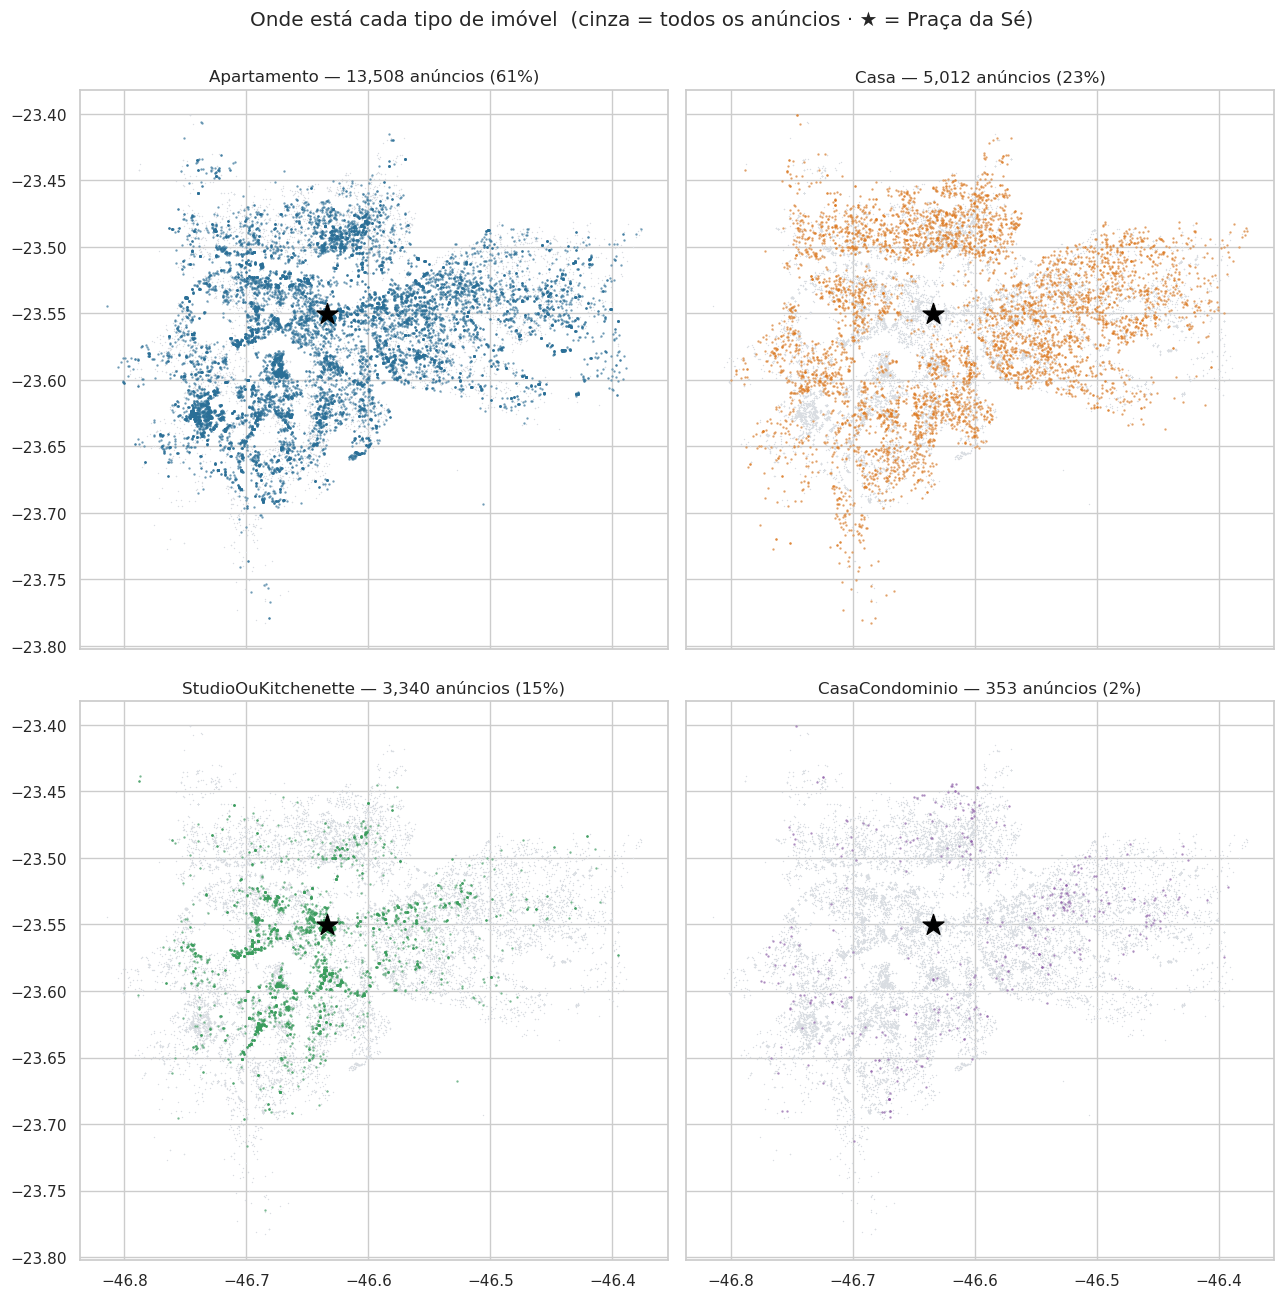

Distância mediana ao centro (km) por tipo:
type
Apartamento            8.80
Casa                  10.20
StudioOuKitchenette    6.50
CasaCondominio        11.00


In [31]:
CENTRO = (-23.5503, -46.6340)   # Praça da Sé (marco zero)


def haversine_km(lat, lon, lat0, lon0):
    lat, lon, lat0, lon0 = map(np.radians, (lat, lon, lat0, lon0))
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat) * np.cos(lat0) * np.sin((lon - lon0) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))


df["dist_centro_km"] = haversine_km(df["lat"], df["lon"], *CENTRO)

fig, axes = plt.subplots(2, 2, figsize=(13, 13), sharex=True, sharey=True)
for ax, tipo in zip(axes.flat, tipos):
    sub = df[df["type"] == tipo]
    ax.scatter(df["lon"], df["lat"], s=1, color="#d9dde2", linewidths=0)
    ax.scatter(sub["lon"], sub["lat"], s=3, color=paleta[tipo], alpha=0.6, linewidths=0)
    ax.scatter(CENTRO[1], CENTRO[0], marker="*", s=250, color="black", zorder=5)
    ax.set_aspect(1 / np.cos(np.radians(-23.55)))
    ax.set_title(f"{tipo} — {len(sub):,} anúncios ({len(sub) / len(df):.0%})")
fig.suptitle("Onde está cada tipo de imóvel  (cinza = todos os anúncios · ★ = Praça da Sé)", y=1.0)
plt.tight_layout()
plt.show()

print("Distância mediana ao centro (km) por tipo:")
print(df.groupby("type")["dist_centro_km"].median().reindex(tipos).round(1).to_string())

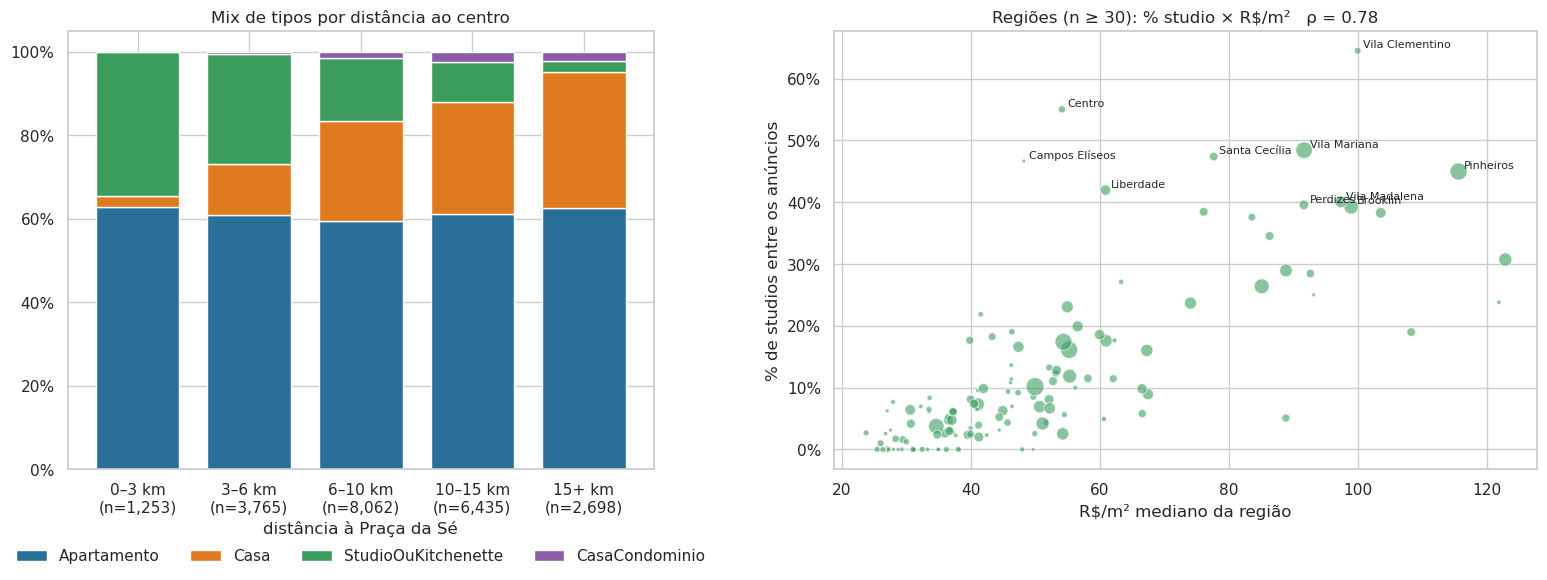

Mix de tipos por faixa de distância:
type          Apartamento  Casa  StudioOuKitchenette  CasaCondominio
faixa_centro                                                        
0–3 km              62.90  2.60                34.40            0.20
3–6 km              61.00 12.10                26.40            0.50
6–10 km             59.50 23.80                15.30            1.40
10–15 km            61.20 26.80                 9.50            2.50
15+ km              62.50 32.70                 2.60            2.10

Spearman % studio × R$/m² da região : ρ = 0.78 (p = 8.3e-29, 133 regiões)
Spearman % studio × distância ao centro: ρ = -0.66 (p = 6.6e-18)

Regiões com maior % de studios:
                   n  pct_studio  rent_m2  dist
regionName                                     
Vila Clementino   93        0.65   100.00  5.15
Centro           109        0.55    54.17  0.92
Vila Mariana     574        0.48    91.69  4.21
Santa Cecília    154        0.47    77.68  1.63
Campos Elíseos    3

In [32]:
from scipy import stats

faixas = [0, 3, 6, 10, 15, np.inf]
rotulos = ["0–3 km", "3–6 km", "6–10 km", "10–15 km", "15+ km"]
df["faixa_centro"] = pd.cut(df["dist_centro_km"], faixas, labels=rotulos, right=False)

mix = pd.crosstab(df["faixa_centro"], df["type"], normalize="index")[tipos]
n_faixa = df["faixa_centro"].value_counts().reindex(rotulos)

reg_tipo = (
    df.groupby("regionName")
    .agg(n=("id", "size"),
         pct_studio=("type", lambda s: (s == "StudioOuKitchenette").mean()),
         rent_m2=("rent_m2", "median"),
         dist=("dist_centro_km", "median"))
    .query("n >= 30")
)
rho_m2, p_m2 = stats.spearmanr(reg_tipo["rent_m2"], reg_tipo["pct_studio"])
rho_dist, p_dist = stats.spearmanr(reg_tipo["dist"], reg_tipo["pct_studio"])

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.2]})

mix.plot.bar(stacked=True, ax=axes[0], color=[paleta[t] for t in tipos], width=0.75,
             edgecolor="white", linewidth=1)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].set_xticklabels([f"{r}\n(n={n:,})" for r, n in n_faixa.items()], rotation=0)
axes[0].set_xlabel("distância à Praça da Sé")
axes[0].set_title("Mix de tipos por distância ao centro")
axes[0].legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False)

ax = axes[1]
ax.scatter(reg_tipo["rent_m2"], reg_tipo["pct_studio"], s=reg_tipo["n"] / 4,
           color=paleta["StudioOuKitchenette"], alpha=0.6, edgecolor="white", linewidth=0.8)
for nome, r in reg_tipo.nlargest(10, "pct_studio").iterrows():
    ax.annotate(nome, (r["rent_m2"], r["pct_studio"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("R$/m² mediano da região")
ax.set_ylabel("% de studios entre os anúncios")
ax.set_title(f"Regiões (n ≥ 30): % studio × R$/m²   ρ = {rho_m2:.2f}")
plt.tight_layout()
plt.show()

print("Mix de tipos por faixa de distância:")
print((mix * 100).round(1).to_string())
print(f"\nSpearman % studio × R$/m² da região : ρ = {rho_m2:.2f} (p = {p_m2:.1e}, {len(reg_tipo)} regiões)")
print(f"Spearman % studio × distância ao centro: ρ = {rho_dist:.2f} (p = {p_dist:.1e})")
print("\nRegiões com maior % de studios:")
print(reg_tipo.nlargest(10, "pct_studio").round(2).to_string())

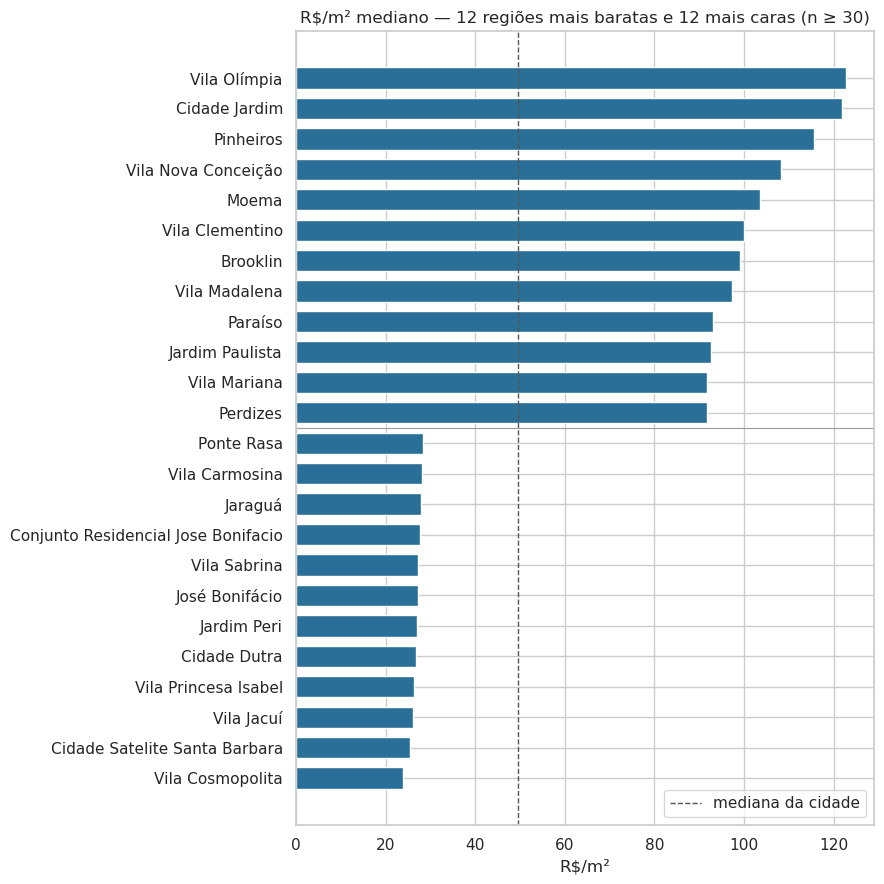

Razão entre a região mais cara e a mais barata (R$/m²): 5.2x


In [26]:
reg = (
    df.groupby("regionName")
    .agg(n=("rent", "size"), rent_mediana=("rent", "median"), rent_m2_mediana=("rent_m2", "median"))
    .query("n >= 30")
    .sort_values("rent_m2_mediana")
)
sel = pd.concat([reg.head(12), reg.tail(12)])

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(sel.index, sel["rent_m2_mediana"], color=COR, height=0.7)
ax.axvline(df["rent_m2"].median(), color="#555", ls="--", lw=1, label="mediana da cidade")
ax.axhline(11.5, color="#999", lw=0.8)
ax.set_title("R$/m² mediano — 12 regiões mais baratas e 12 mais caras (n ≥ 30)")
ax.set_xlabel("R$/m²")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"Razão entre a região mais cara e a mais barata (R$/m²): "
      f"{reg['rent_m2_mediana'].max() / reg['rent_m2_mediana'].min():.1f}x")

### 9.4 Correlação (Spearman) com `log_rent`

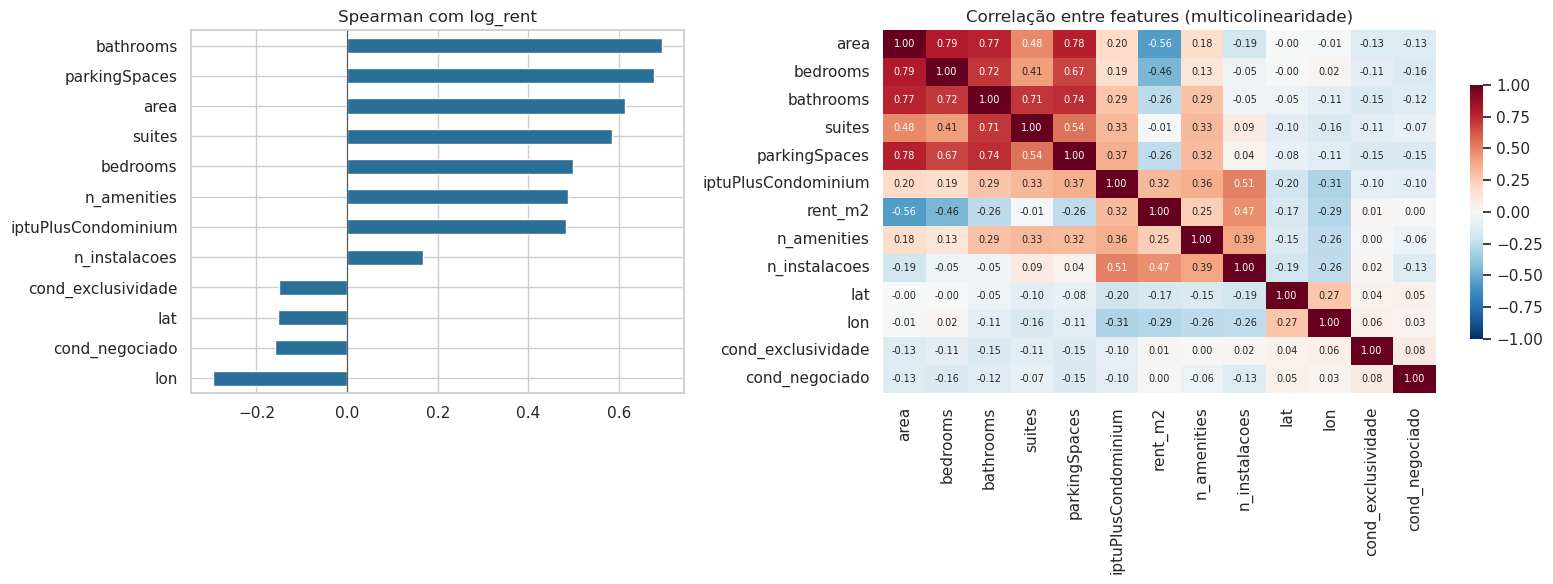

In [27]:
cols_corr = NUM_FEATS + ["dist_centro_km", "lat", "lon", "cond_exclusividade", "cond_negociado"]
corr = df[cols_corr + ["log_rent"]].astype(float).corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.4]})
corr["log_rent"].drop(["log_rent", "rent_m2"]).sort_values().plot.barh(ax=axes[0], color=COR)
axes[0].set_title("Spearman com log_rent")
axes[0].axvline(0, color="#555", lw=0.8)

sns.heatmap(corr.drop(index="log_rent", columns="log_rent"), cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, ax=axes[1], cbar_kws={"shrink": 0.7})
axes[1].set_title("Correlação entre features (multicolinearidade)")
plt.tight_layout()
plt.show()

### 9.5 Efeito de cada amenity / instalação

Comparação ingênua: mediana de **R$/m²** com vs. sem o item. Usar R$/m² neutraliza parte do efeito de tamanho.
Ainda é uma associação, não causa — por exemplo, piscina e academia aparecem juntas em condomínios novos e caros.
A separação dos efeitos fica para a regressão do notebook 02.

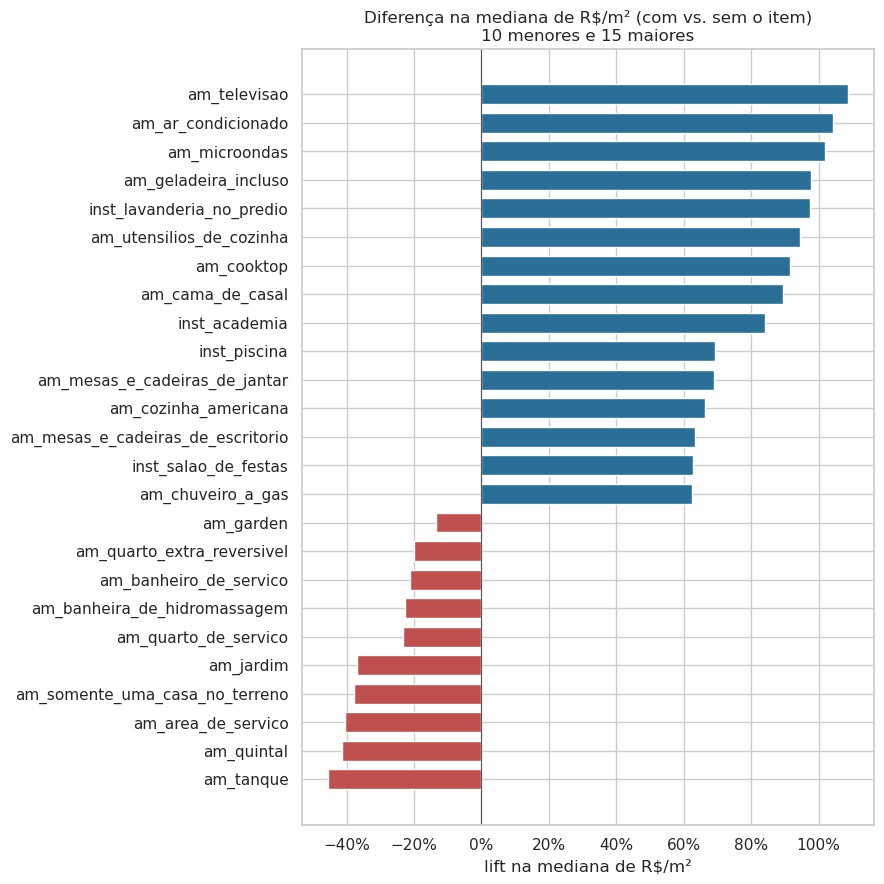

In [28]:
efeitos = []
for col in AM_COLS + INST_COLS:
    com = df.loc[df[col] == 1, "rent_m2"]
    sem = df.loc[df[col] == 0, "rent_m2"]
    efeitos.append({"item": col, "freq": len(com) / len(df),
                    "lift_mediana": com.median() / sem.median() - 1})
efeitos = pd.DataFrame(efeitos).sort_values("lift_mediana")

sel = pd.concat([efeitos.head(10), efeitos.tail(15)])
fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(sel["item"], sel["lift_mediana"],
        color=np.where(sel["lift_mediana"] >= 0, "#2a6f97", "#c0504d"), height=0.7)
ax.axvline(0, color="#555", lw=0.8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Diferença na mediana de R$/m² (com vs. sem o item)\n10 menores e 15 maiores")
ax.set_xlabel("lift na mediana de R$/m²")
plt.tight_layout()
plt.show()

### 9.6 Mais cortes por tipo de imóvel

Como o mix de tipos muda com a localização e o tamanho, várias comparações da 9.2 e da 9.5 misturam efeitos.
Aqui cada comparação é feita **dentro do tipo**.

#### 9.6.1 R$/m² × distância ao centro

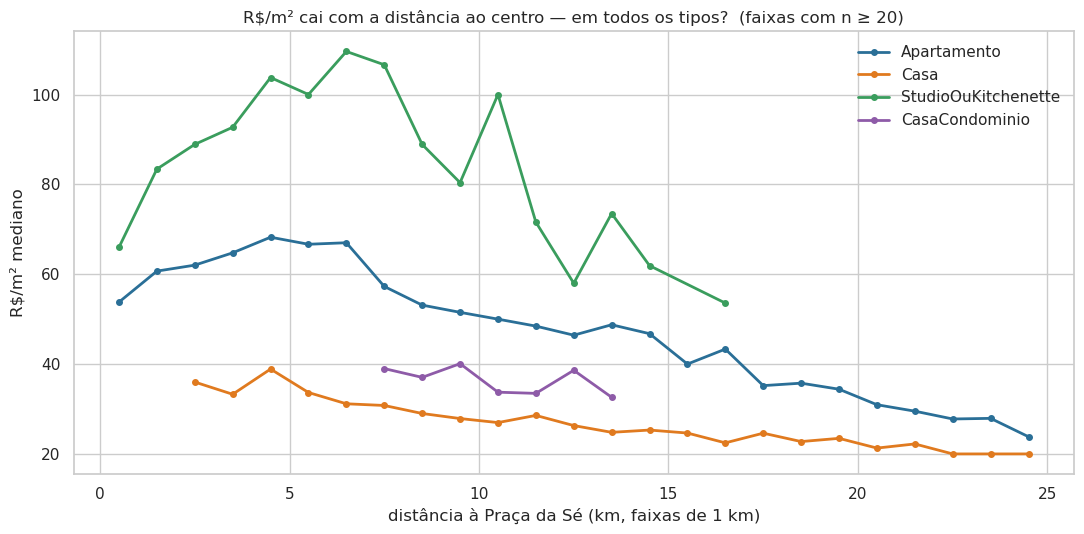

Spearman distância × R$/m² (todos): ρ = -0.42 (p = 0.0e+00)
  Apartamento          ρ = -0.40
  Casa                 ρ = -0.27
  StudioOuKitchenette  ρ = -0.11
  CasaCondominio       ρ = -0.26


In [33]:
df["dist_bin"] = df["dist_centro_km"].clip(upper=24.99).floordiv(1) + 0.5

fig, ax = plt.subplots(figsize=(11, 5.5))
for tipo in tipos:
    g = (df[df["type"] == tipo].groupby("dist_bin")["rent_m2"]
         .agg(mediana="median", n="size").query("n >= 20"))
    ax.plot(g.index, g["mediana"], color=paleta[tipo], lw=2, marker="o", ms=4, label=tipo)
ax.set_xlabel("distância à Praça da Sé (km, faixas de 1 km)")
ax.set_ylabel("R$/m² mediano")
ax.set_title("R$/m² cai com a distância ao centro — em todos os tipos?  (faixas com n ≥ 20)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

rho, p = stats.spearmanr(df["dist_centro_km"], df["rent_m2"])
print(f"Spearman distância × R$/m² (todos): ρ = {rho:.2f} (p = {p:.1e})")
for tipo in tipos:
    s = df[df["type"] == tipo]
    print(f"  {tipo:<20} ρ = {stats.spearmanr(s['dist_centro_km'], s['rent_m2'])[0]:.2f}")

#### 9.6.2 R$/m² × tamanho

Se o m² fica mais caro em imóveis pequenos, o studio "paga" um prêmio por m² — consistente com a elasticidade < 1 da 9.1.

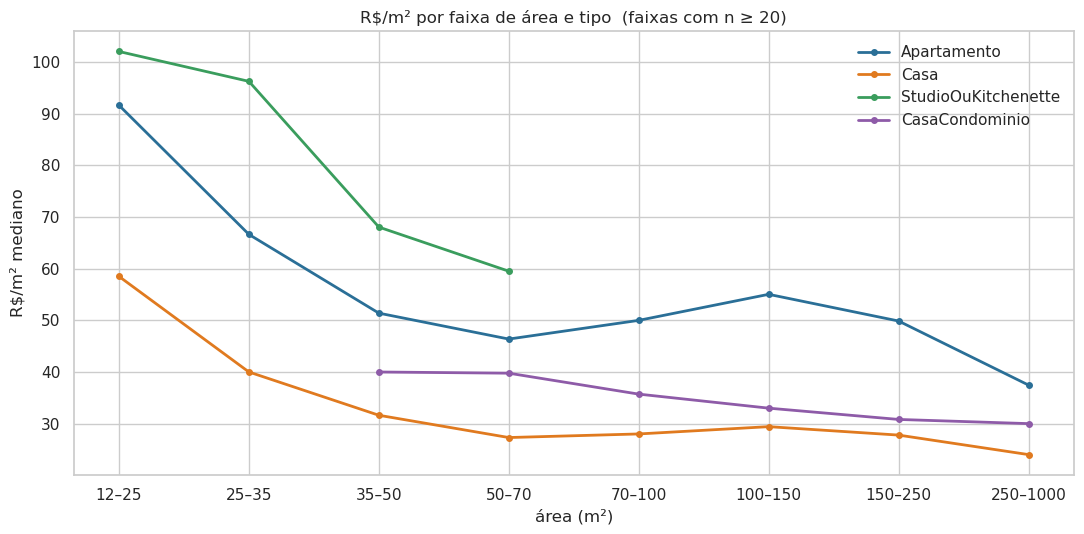

type      Apartamento  Casa  StudioOuKitchenette  CasaCondominio
x                                                               
12–25           91.70 58.50               102.10             NaN
25–35           66.60 40.00                96.30             NaN
35–50           51.40 31.60                68.10           40.00
50–70           46.40 27.30                59.50           39.80
70–100          50.00 28.00                  NaN           35.70
100–150         55.00 29.40                  NaN           33.00
150–250         49.90 27.80                  NaN           30.80
250–1000        37.50 24.00                  NaN           30.00


In [34]:
bins_area = [12, 25, 35, 50, 70, 100, 150, 250, 1000]
df["area_bin"] = pd.cut(df["area"], bins_area, right=False)

tab = (df.groupby(["area_bin", "type"], observed=True)["rent_m2"]
       .agg(mediana="median", n="size").query("n >= 20").reset_index())
tab["x"] = tab["area_bin"].map(lambda iv: f"{int(iv.left)}–{int(iv.right)}")
ordem_x = [f"{a}–{b}" for a, b in zip(bins_area[:-1], bins_area[1:])]

fig, ax = plt.subplots(figsize=(11, 5.5))
for tipo in tipos:
    t = tab[tab["type"] == tipo].set_index("x").reindex(ordem_x)
    ax.plot(ordem_x, t["mediana"], color=paleta[tipo], lw=2, marker="o", ms=4, label=tipo)
ax.set_xlabel("área (m²)")
ax.set_ylabel("R$/m² mediano")
ax.set_title("R$/m² por faixa de área e tipo  (faixas com n ≥ 20)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print(tab.pivot(index="x", columns="type", values="mediana").reindex(ordem_x)[tipos].round(1).to_string())

#### 9.6.3 Mobília, pet e piscina — efeito dentro do tipo

Na 9.5, itens de mobília apareciam com +60% a +100% de R$/m². Parte disso é composição: studios são mais mobiliados **e** têm R$/m² maior.
Comparando dentro do mesmo tipo, o efeito que sobra é mais honesto (ainda sem controlar localização — isso fica para a regressão do 02).

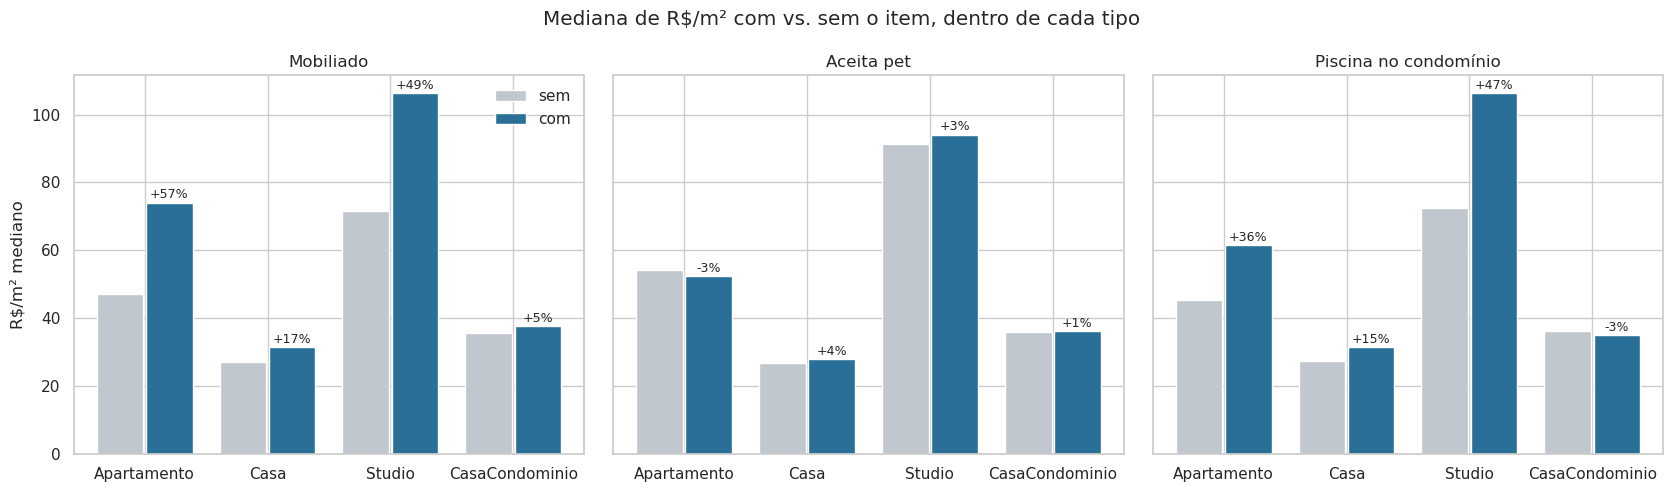


Mobiliado
                    % com  R$/m² com  R$/m² sem    lift p (Mann-Whitney)
type                                                                    
Apartamento           30%      74.10      47.20  +56.9%          0.0e+00
Casa                  16%      31.60      26.90  +17.2%          4.7e-23
StudioOuKitchenette   57%     106.20      71.40  +48.8%         7.7e-156
CasaCondominio        14%      37.60      35.70   +5.4%          2.9e-01

Aceita pet
                    % com  R$/m² com  R$/m² sem   lift p (Mann-Whitney)
type                                                                   
Apartamento           77%      52.50      54.20  -3.1%          4.0e-05
Casa                  71%      28.00      26.90  +4.3%          3.0e-02
StudioOuKitchenette   63%      94.10      91.30  +3.1%          4.9e-02
CasaCondominio        75%      36.20      35.80  +1.2%          6.2e-01

Piscina no condomínio
                    % com  R$/m² com  R$/m² sem    lift p (Mann-Whitney)
type       

In [35]:
def efeito_por_tipo(col: str) -> pd.DataFrame:
    linhas = []
    for tipo in tipos:
        s = df[df["type"] == tipo]
        com, sem = s.loc[s[col] == 1, "rent_m2"], s.loc[s[col] == 0, "rent_m2"]
        if min(len(com), len(sem)) < 30:
            continue
        linhas.append({"type": tipo, "% com": len(com) / len(s),
                       "R$/m² com": com.median(), "R$/m² sem": sem.median(),
                       "lift": com.median() / sem.median() - 1,
                       "p (Mann-Whitney)": stats.mannwhitneyu(com, sem).pvalue})
    return pd.DataFrame(linhas).set_index("type")


df["mobiliado"] = df["isFurnished"].fillna(False).astype(int)
ITENS = {"mobiliado": "Mobiliado",
         "am_pode_ter_animais_de_estimacao": "Aceita pet",
         "inst_piscina": "Piscina no condomínio"}

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
resultados = {}
for ax, (col, nome) in zip(axes, ITENS.items()):
    r = efeito_por_tipo(col)
    resultados[nome] = r
    x = np.arange(len(r))
    ax.bar(x - 0.2, r["R$/m² sem"], width=0.38, color="#c0c7cf", label="sem")
    ax.bar(x + 0.2, r["R$/m² com"], width=0.38, color=COR, label="com")
    for xi, lift in zip(x, r["lift"]):
        ax.annotate(f"{lift:+.0%}", (xi + 0.2, r["R$/m² com"].iloc[xi]), ha="center",
                    xytext=(0, 3), textcoords="offset points", fontsize=9)
    ax.set_xticks(x, [t.replace("OuKitchenette", "") for t in r.index])
    ax.set_title(nome)
axes[0].set_ylabel("R$/m² mediano")
axes[0].legend(frameon=False)
fig.suptitle("Mediana de R$/m² com vs. sem o item, dentro de cada tipo")
plt.tight_layout()
plt.show()

for nome, r in resultados.items():
    print(f"\n{nome}")
    print(r.assign(**{"% com": r["% com"].map("{:.0%}".format), "lift": r["lift"].map("{:+.1%}".format),
                      "p (Mann-Whitney)": r["p (Mann-Whitney)"].map("{:.1e}".format)}).round(1).to_string())

#### 9.6.4 Condomínio + IPTU × aluguel

`iptuPlusCondominium` é a feature candidata mais forte que não vem da planta do imóvel. Quanto ela "explica" do aluguel?

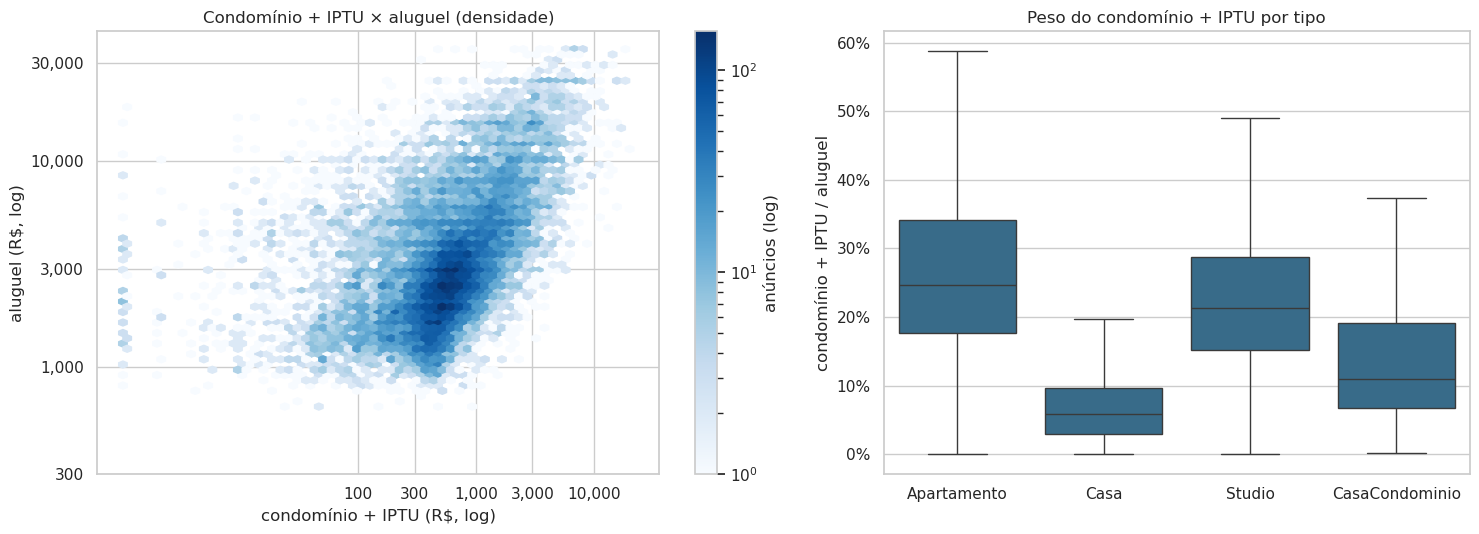

Spearman condomínio+IPTU × aluguel (só > 0): ρ = 0.52
Anúncios com condomínio+IPTU = 0: 7.5%
type
Casa                  75.20
Apartamento           14.70
StudioOuKitchenette    7.90
CasaCondominio         2.20


In [36]:
c = df[df["iptuPlusCondominium"] > 0].copy()
c["razao_condo"] = c["iptuPlusCondominium"] / c["rent"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
hb = axes[0].hexbin(np.log10(c["iptuPlusCondominium"]), np.log10(c["rent"]), gridsize=60,
                    cmap="Blues", mincnt=1, bins="log")
ticks = [100, 300, 1000, 3000, 10000, 30000]
axes[0].set_xticks(np.log10(ticks[:-1]), [f"{t:,}" for t in ticks[:-1]])
axes[0].set_yticks(np.log10(ticks[1:]), [f"{t:,}" for t in ticks[1:]])
axes[0].set_xlabel("condomínio + IPTU (R$, log)")
axes[0].set_ylabel("aluguel (R$, log)")
axes[0].set_title("Condomínio + IPTU × aluguel (densidade)")
fig.colorbar(hb, ax=axes[0], label="anúncios (log)")

sns.boxplot(data=c, x="type", y="razao_condo", order=tipos, ax=axes[1], color=COR, showfliers=False)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[1].set_xticks(range(len(tipos)), [t.replace("OuKitchenette", "") for t in tipos])
axes[1].set_xlabel("")
axes[1].set_ylabel("condomínio + IPTU / aluguel")
axes[1].set_title("Peso do condomínio + IPTU por tipo")
plt.tight_layout()
plt.show()

rho, _ = stats.spearmanr(c["iptuPlusCondominium"], c["rent"])
print(f"Spearman condomínio+IPTU × aluguel (só > 0): ρ = {rho:.2f}")
print(f"Anúncios com condomínio+IPTU = 0: {(df['iptuPlusCondominium'] == 0).mean():.1%}")
print((df[df['iptuPlusCondominium'] == 0]['type'].value_counts(normalize=True) * 100).round(1).to_string())

#### 9.6.5 Quanto do preço a localização sozinha explica?

Comparação simples: R² de `log(rent)` explicado só pela média da região vs. só pela área.
É uma prévia (sem validação cruzada, otimista) que antecipa o peso de cada bloco de feature no 04.

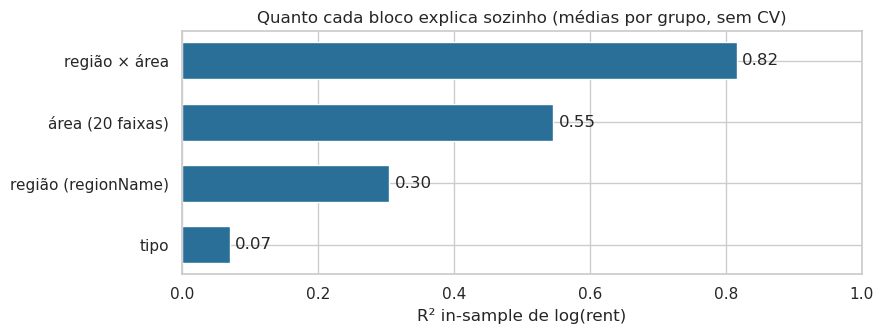

In [37]:
def r2_por_grupo(y: pd.Series, grupo: pd.Series) -> float:
    pred = y.groupby(grupo).transform("mean")
    return 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()


y = df["log_rent"]
area_dec = pd.qcut(df["area"], 20, duplicates="drop")
blocos = {
    "região (regionName)": r2_por_grupo(y, df["regionName"]),
    "área (20 faixas)": r2_por_grupo(y, area_dec),
    "tipo": r2_por_grupo(y, df["type"]),
    "região × área": r2_por_grupo(y, df["regionName"].astype(str) + "|" + area_dec.astype(str)),
}
r2 = pd.Series(blocos).sort_values()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(r2.index, r2.values, color=COR, height=0.6)
for i, v in enumerate(r2.values):
    ax.annotate(f"{v:.2f}", (v, i), xytext=(4, 0), textcoords="offset points", va="center")
ax.set_xlim(0, 1)
ax.set_xlabel("R² in-sample de log(rent)")
ax.set_title("Quanto cada bloco explica sozinho (médias por grupo, sem CV)")
plt.tight_layout()
plt.show()

In [38]:
# Colunas auxiliares só de EDA (dist_centro_km fica na base)
df = df.drop(columns=["faixa_centro", "dist_bin", "area_bin", "mobiliado"])

## 10. Resumo e hipóteses para o notebook 02 (inferência)

Hipóteses que a EDA levanta e o 02 deve testar:

| # | Hipótese | Teste sugerido |
|---|---|---|
| H1 | `log(rent)` cresce com `log(area)` com elasticidade < 1 (m² extra vale menos em imóvel grande) | OLS log-log, IC da inclinação |
| H2 | O R$/m² difere entre regiões | Kruskal-Wallis + post-hoc Dunn (resíduos não normais) |
| H3 | Imóvel mobiliado tem R$/m² maior, controlando por tipo e área | Mann-Whitney por estrato + OLS com controle |
| H4 | O tipo de imóvel tem efeito controlando a área | OLS com `type` + `log(area)` |
| H5 | Aceitar pet altera o preço | Mann-Whitney + OLS com controle |
| H6 | Instalações de condomínio (piscina, academia) mantêm efeito depois de controlar localização e área | OLS com efeito fixo de região |
| H7 | Multicolinearidade entre área, quartos, banheiros e vagas | VIF |
| H8 | Proximidade de metrô aumenta o R$/m² | Spearman + OLS (depois dos POIs no 03) |
| H9 | A relação R$/m² × distância ao centro não é monotônica (pico em 4–7 km, não no marco zero) | OLS com spline/polinômio de `dist_centro_km` vs. termo linear (teste F) |
| H10 | Mobília e piscina mantêm efeito sobre R$/m² dentro do tipo **e** da região | OLS com efeito fixo de região + interação com `type` |
| H11 | A proporção de studios de uma região está associada ao seu R$/m² | Spearman por região (ρ = 0,78 na EDA) + regressão ponderada por n |

**Limitações registradas**
- Alvo censurado em R$ 35 mil (teto da busca do portal).
- Preço de **anúncio**, não de contrato fechado.
- Amostra de um portal só (QuintoAndar): pode não representar todo o mercado.

## 11. Salvar

In [39]:
# Checagens mínimas antes de salvar (viram schema Pandera no pipeline)
assert df["id"].is_unique
assert df["rent"].between(500, 35_000).all()
assert df["area"].between(12, 1000).all()
assert df[["lat", "lon"]].notna().all().all()
assert not {"totalCost", "yield", "salePrice"} & set(df.columns), "coluna de vazamento na base"

df = df.reset_index(drop=True)
df.to_parquet(OUT_CLEAN, index=False)
custo_bairro.to_parquet(OUT_CUSTO, index=False)

print(f"{OUT_CLEAN.relative_to(ROOT)}  -> {df.shape}")
print(f"{OUT_CUSTO.relative_to(ROOT)} -> {custo_bairro.shape}")

data/interim/aluguel_sp_clean.parquet  -> (22213, 96)
data/interim/aluguel_custo_extra_bairro.parquet -> (1249, 8)


In [40]:
pd.DataFrame(log_limpeza)

,etapa,linhas,removidas
0,bruto,30413,0
1,city == São Paulo,24250,6163
2,forRent == True,23505,745
3,lat/lon dentro da capital,23504,1
4,remove duplicatas (chave física + preço),22501,1003
5,remove nulos em area/bedrooms/bathrooms,22498,3
6,12 <= area <= 1000,22453,45
7,bathrooms >= 1,22450,3
8,bedrooms >= 1 (exceto studio),22436,14
9,"rent/m² entre P0,5 e P99,5",22213,223


## 12. Relatório de insights

**Base:** 22.213 anúncios de aluguel residencial na cidade de São Paulo (QuintoAndar), depois de remover 27% do bruto — outras cidades (6.163), anúncios só de venda (745), republicações (1.003) e erros de cadastro (~300).
Valores são **medianas** e associações descritivas; efeitos causais/controlados ficam para o notebook 02.

---

### 1. Localização é o principal fator — mas "central" não é "nobre"

- O R$/m² mediano varia **5,2×** entre a região mais barata e a mais cara (n ≥ 30).
- O R$/m² **não é máximo no marco zero**: sobe de ~54 R$/m² (0–1 km) até o **pico em 4–7 km** (~67 R$/m² para apartamentos) e depois cai até ~24 R$/m² a 25 km.
  O centro histórico (Sé, República, Campos Elíseos, Liberdade) é mais barato que o anel Pinheiros – Vila Mariana – Itaim – Brooklin.
- Consequência: `dist_centro_km` sozinha é uma feature fraca e não-linear (Spearman −0,42). Para o modelo, coordenadas brutas + modelo de árvore, ou distância a **polos de valor** (Faria Lima, Paulista, Berrini), devem funcionar melhor que a distância à Sé.
- Prévia de poder explicativo (R² in-sample, sem CV): região sozinha explica **0,30** do `log(rent)`, área sozinha **0,55**, e região × área **0,82**. O último é otimista (muitas células pequenas), mas confirma que localização e tamanho juntos carregam a maior parte do sinal.

### 2. Studios: hipótese confirmada, com dois perfis distintos

> *Hipótese: studios estão mais concentrados em áreas nobres ou centrais.*

- **Centrais — sim.** Studios são 34% dos anúncios a até 3 km da Sé, 26% entre 3 e 6 km, e apenas 3% acima de 15 km. Distância mediana ao centro: studio 6,5 km vs. apartamento 8,8 km e casa 10,2 km.
- **Nobres — sim.** Por região, a fatia de studios acompanha o R$/m² mediano: **Spearman ρ = 0,78** (p < 10⁻²⁸, 133 regiões).
- Mas há **dois mercados de studio**:
  - *Centro histórico* — Centro (55% dos anúncios são studios), Campos Elíseos (47%), Liberdade (42%): R$/m² de 48 a 61, abaixo da mediana da cidade.
  - *Eixo nobre/jovem* — Vila Clementino (65%), Vila Mariana (48%), Pinheiros (45%), Vila Madalena (40%), Brooklin (39%): R$/m² de 92 a 116.
- O studio tem o **R$/m² mais alto de todos os tipos** em qualquer faixa de área comparável (ex.: 25–35 m²: studio 96 vs. apartamento 67 R$/m²) e é o tipo menos sensível à distância (ρ = −0,11), porque o preço é ditado pelo micro-local.

### 3. Tamanho: o m² fica mais barato à medida que o imóvel cresce

- Elasticidade log-log aluguel × área ≈ **0,61**: dobrar a área aumenta o aluguel em ~53%, não 100%.
- Apartamentos: de 92 R$/m² (12–25 m²) para 46–50 R$/m² a partir de 50 m². Casas: de 59 para 24–28 R$/m².
- Área, quartos, banheiros e vagas são fortemente correlacionados entre si (Spearman 0,67 a 0,79) → multicolinearidade a tratar no 02 (VIF) e cuidado na interpretação de modelos lineares.

### 4. Atributos do imóvel

| Atributo | Efeito na mediana de R$/m² (dentro do tipo) | Leitura |
|---|---|---|
| **Mobiliado** | Apartamento +57%, Studio +49%, Casa +17%, Casa em condomínio +5% (n.s.) | Efeito grande e consistente, mas ainda confundido com localização (mobiliados se concentram nas regiões caras) |
| **Piscina no condomínio** | Apartamento +36%, Studio +47%, Casa +15% | Proxy de prédio novo/alto padrão; tende a perder força ao controlar região |
| **Aceita pet** | −3% a +4% | Praticamente sem efeito no preço — útil na UI, irrelevante para o modelo |
| Itens "de casa antiga" (tanque, quintal, área de serviço) | −40% a −46% na comparação geral | Marcam casas e imóveis mais antigos/periféricos, não causam preço menor |

- A comparação geral (9.5) superestima mobília: TV, ar-condicionado e micro-ondas aparecem com +100% porque marcam studios mobiliados em regiões nobres. Comparar **dentro do tipo** reduz, mas não elimina, esse viés.

### 5. Condomínio + IPTU e custo total (para a UI)

- `iptuPlusCondominium` tem Spearman 0,52 com o aluguel: é informativo, mas exige que o usuário informe o valor. Decisão (usar ou não como feature) fica para o 04, comparando os dois cenários.
- 7,5% dos anúncios têm condomínio + IPTU = 0 — 75% deles são casas (sem condomínio). É valor real, não ausente.
- **Custo extra** `(totalCost − rent) / rent`: mediana da cidade **23,6%** (≈ R$ 644). Varia de ~18% (Vila Prudente) a ~32% (Itaim Bibi) entre os bairros com mais anúncios, e chega a ~50% em Higienópolis (prédios antigos e grandes).
- Tabela salva em `data/interim/aluguel_custo_extra_bairro.parquet` com fallback bairro → região → cidade. Na UI: *custo total estimado = aluguel previsto × (1 + % extra do bairro)*, exibindo também a faixa P25–P75.

### 6. Implicações para a modelagem

1. **Alvo:** modelar `log(rent)` (assimetria cai de 3,1 para 0,75) e reportar MAE/MAPE em **R$**.
2. **Validação:** `GroupKFold` por localização (coordenada ou região) para não vazar o mesmo imóvel/prédio entre treino e teste; comparar com KFold aleatório.
3. **Features prioritárias:** área (log), localização (lat/lon, target encoding de região dentro do CV, distância a polos de valor), tipo, mobiliado, banheiros/vagas, instalações do condomínio.
4. **Interações:** tipo × área e tipo × localização importam (studio se comporta diferente) → favorece modelos de árvore (LightGBM/XGBoost/CatBoost).
5. **Baseline honesto:** mediana de R$/m² da região × área. Qualquer modelo precisa bater esse número.

### 7. Limitações

- Preço **anunciado**, não de contrato fechado; um único portal (QuintoAndar), cujo público pode não representar o mercado inteiro.
- Alvo **censurado em R$ 35 mil** (teto de busca do portal): previsões no topo serão subestimadas.
- `neighbourhood` tem 1.257 grafias com mediana de 4 anúncios por bairro → pouco confiável sozinho; `regionName` (321 níveis) é a granularidade mais útil.
- Todas as diferenças acima são associações. A separação de efeitos (mobília vs. localização, piscina vs. idade do prédio) é o objetivo do notebook 02.
